In [ ]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification with Sentiment-Enhanced Severity Prediction
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    XLMRobertaModel,
    XLMRobertaTokenizer,
    XLMRobertaConfig,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION
# ============================================================================

import os
import torch


class Config:
    """Configuration settings for HiENBERT training with optimized performance"""

    # =========================================================================
    # BASE MODEL
    # =========================================================================

    BASE_MODEL = 'indicbert'
    # Options:
    #   'indicbert'
    #   'xlm-roberta'

    INDICBERT_PATH = "ai4bharat/indic-bert"
    XLMBERT_PATH = "xlm-roberta-base"

    # =========================================================================
    # PROJECT ROOT DIRECTORY
    # =========================================================================
    # The notebook is currently running from:
    #
    # C:\Users\CH.SC\U4CSE23160\Final_Year_Project\
    # BERT_Project_Backup\Original Dataset\HiENBERT
    #
    # Therefore os.getcwd() gives the correct project directory.

    PROJECT_DIR = os.getcwd()

    # =========================================================================
    # INPUT DATASET DIRECTORY
    # =========================================================================

    DATA_DIR = os.path.join(
        PROJECT_DIR,
        "dataset"
    )

    TRAIN_PATH = os.path.join(
        DATA_DIR,
        "train",
        "train.csv"
    )

    DEV_PATH = os.path.join(
        DATA_DIR,
        "dev",
        "dev.csv"
    )

    TEST_PATH = os.path.join(
        DATA_DIR,
        "test",
        "test.csv"
    )

    # =========================================================================
    # OUTPUT DIRECTORY
    # =========================================================================
    # Everything generated by this notebook will be stored inside:
    #
    # HiENBERT/
    #     hienbert_indicbert_results/
    #
    # or
    #
    # HiENBERT/
    #     hienbert_xlm-roberta_results/

    BASE_DIR = os.path.join(
        PROJECT_DIR,
        f"hienbert_{BASE_MODEL}_results"
    )

    # =========================================================================
    # OUTPUT SUBDIRECTORIES
    # =========================================================================

    MODEL_DIR = os.path.join(
        BASE_DIR,
        "models"
    )

    VISUALIZATION_DIR = os.path.join(
        BASE_DIR,
        "visualizations"
    )

    LOG_DIR = os.path.join(
        BASE_DIR,
        "logs"
    )

    RESULTS_DIR = os.path.join(
        BASE_DIR,
        "results"
    )

    CHECKPOINT_DIR = os.path.join(
        BASE_DIR,
        "checkpoints"
    )

    PREDICTION_DIR = os.path.join(
        BASE_DIR,
        "predictions"
    )

    EMBEDDING_DIR = os.path.join(
        BASE_DIR,
        "embeddings"
    )

    # =========================================================================
    # TRAINING PARAMETERS
    # =========================================================================

    MAX_LENGTH = 128

    BATCH_SIZE = 32

    EPOCHS = 20

    LEARNING_RATE = 2e-5

    DROPOUT = 0.3

    WEIGHT_DECAY = 0.01

    GRADIENT_ACCUMULATION_STEPS = 1

    WARMUP_RATIO = 0.1

    # =========================================================================
    # MIXED PRECISION
    # =========================================================================

    USE_AMP = True

    # =========================================================================
    # IMBALANCE HANDLING
    # =========================================================================

    USE_CLASS_WEIGHTS = True

    USE_FOCAL_LOSS = True

    USE_WEIGHTED_SAMPLER = True

    FOCAL_ALPHA = 0.25

    FOCAL_GAMMA = 2.0

    # =========================================================================
    # SEVERITY ENHANCEMENT
    # =========================================================================

    ENHANCE_SEVERITY = True

    SENTIMENT_THRESHOLD = 0.5

    # =========================================================================
    # DEVICE
    # =========================================================================

    DEVICE = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # =========================================================================
    # RANDOM SEED
    # =========================================================================

    SEED = 42

    # =========================================================================
    # HUGGING FACE TOKEN
    # =========================================================================
    # IMPORTANT:
    # Do NOT hard-code your Hugging Face token here.
    #
    # Set it using an environment variable instead:
    #
    # Windows PowerShell:
    #   $env:HF_TOKEN="your_new_token"
    #
    # Or set it inside Python before running the model:
    #   os.environ["HF_TOKEN"] = "your_new_token"
    #
    # The exposed token from your previous code should be revoked.
    # HuggingFace token
    HF_TOKEN = os.getenv("HF_TOKEN")

    # =========================================================================
    # CREATE ALL DIRECTORIES
    # =========================================================================

    for dir_path in [
        BASE_DIR,
        MODEL_DIR,
        VISUALIZATION_DIR,
        LOG_DIR,
        RESULTS_DIR,
        CHECKPOINT_DIR,
        PREDICTION_DIR,
        EMBEDDING_DIR
    ]:
        os.makedirs(dir_path, exist_ok=True)


# ============================================================================
# GET MODEL PATH
# ============================================================================

def get_model_path():

    if Config.BASE_MODEL == 'indicbert':
        return Config.INDICBERT_PATH

    elif Config.BASE_MODEL == 'xlm-roberta':
        return Config.XLMBERT_PATH

    else:
        raise ValueError(
            f"Unsupported base model: {Config.BASE_MODEL}"
        )


# ============================================================================
# CONFIGURATION SUMMARY
# ============================================================================

print("=" * 80)
print("HiENBERT CONFIGURATION")
print("=" * 80)

print("\n[PROJECT]")
print(f"Project Directory : {Config.PROJECT_DIR}")

print("\n[MODEL]")
print(f"Base Model        : {Config.BASE_MODEL}")
print(f"Model Path        : {get_model_path()}")

print("\n[INPUT DATASET]")
print(f"Dataset Directory : {Config.DATA_DIR}")
print(f"Train Path        : {Config.TRAIN_PATH}")
print(f"Dev Path          : {Config.DEV_PATH}")
print(f"Test Path         : {Config.TEST_PATH}")

print("\n[OUTPUT]")
print(f"Base Output       : {Config.BASE_DIR}")
print(f"Models            : {Config.MODEL_DIR}")
print(f"Visualizations    : {Config.VISUALIZATION_DIR}")
print(f"Logs              : {Config.LOG_DIR}")
print(f"Results           : {Config.RESULTS_DIR}")
print(f"Checkpoints       : {Config.CHECKPOINT_DIR}")
print(f"Predictions       : {Config.PREDICTION_DIR}")
print(f"Embeddings        : {Config.EMBEDDING_DIR}")

print("\n[TRAINING]")
print(f"Max Length        : {Config.MAX_LENGTH}")
print(f"Batch Size        : {Config.BATCH_SIZE}")
print(f"Epochs            : {Config.EPOCHS}")
print(f"Learning Rate     : {Config.LEARNING_RATE}")
print(f"Dropout           : {Config.DROPOUT}")
print(f"Weight Decay      : {Config.WEIGHT_DECAY}")

print("\n[IMBALANCE HANDLING]")
print(f"Class Weights     : {Config.USE_CLASS_WEIGHTS}")
print(f"Focal Loss        : {Config.USE_FOCAL_LOSS}")
print(f"Weighted Sampler  : {Config.USE_WEIGHTED_SAMPLER}")
print(f"Focal Alpha       : {Config.FOCAL_ALPHA}")
print(f"Focal Gamma       : {Config.FOCAL_GAMMA}")

print("\n[SEVERITY]")
print(f"Enhancement       : {Config.ENHANCE_SEVERITY}")
print(f"Sentiment Threshold: {Config.SENTIMENT_THRESHOLD}")

print("\n[DEVICE]")
print(f"Device            : {Config.DEVICE}")

if torch.cuda.is_available():
    print(f"GPU               : {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version      : {torch.version.cuda}")
else:
    print("GPU               : Not available")

print("\n[DATASET CHECK]")
print(f"Train exists      : {os.path.isfile(Config.TRAIN_PATH)}")
print(f"Dev exists        : {os.path.isfile(Config.DEV_PATH)}")
print(f"Test exists       : {os.path.isfile(Config.TEST_PATH)}")

print("\n[OUTPUT DIRECTORY CHECK]")
print(f"Base exists       : {os.path.isdir(Config.BASE_DIR)}")
print(f"Models exists     : {os.path.isdir(Config.MODEL_DIR)}")
print(f"Results exists    : {os.path.isdir(Config.RESULTS_DIR)}")
print(f"Logs exists       : {os.path.isdir(Config.LOG_DIR)}")
print(f"Checkpoints exist : {os.path.isdir(Config.CHECKPOINT_DIR)}")

print("\n" + "=" * 80)
print("Configuration loaded successfully")
print("=" * 80)

HiENBERT CONFIGURATION

[PROJECT]
Project Directory : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT

[MODEL]
Base Model        : indicbert
Model Path        : ai4bharat/indic-bert

[INPUT DATASET]
Dataset Directory : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\dataset
Train Path        : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\dataset\train\train.csv
Dev Path          : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\dataset\dev\dev.csv
Test Path         : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\dataset\test\test.csv

[OUTPUT]
Base Output       : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results
Models            : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Origina

In [5]:
# ============================================================================
# CELL 3: DATA LOADING WITH IMBALANCE ANALYSIS
# ============================================================================

class DataLoaderWithImbalance:
    """Load data and analyze class imbalance"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
        self.class_weights = {}
        self.original_distribution = {}
        
    def load_data(self):
        """Load train, dev, test datasets"""
        print("Loading datasets...")
        
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(self.train_df)}")
        print(f"Dev samples: {len(self.dev_df)}")
        print(f"Test samples: {len(self.test_df)}")
        
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_imbalance(self, df, label_col, title=""):
        """Analyze and visualize class imbalance"""
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        
        print(f"\n{'='*60}")
        print(f"Class Distribution Analysis - {title}")
        print(f"{'='*60}")
        
        # Store original distribution
        self.original_distribution[label_col] = class_counts.to_dict()
        
        # Print statistics
        for cls, count in class_counts.items():
            pct = class_percentages[cls]
            print(f"  {cls}: {count} samples ({pct:.2f}%)")
        
        # Calculate imbalance metrics
        max_count = class_counts.max()
        min_count = class_counts.min()
        imbalance_ratio = max_count / min_count if min_count > 0 else float('inf')
        
        print(f"\nImbalance Metrics:")
        print(f"  Total classes: {len(class_counts)}")
        print(f"  Majority class size: {max_count}")
        print(f"  Minority class size: {min_count}")
        print(f"  Imbalance ratio: {imbalance_ratio:.2f}:1")
        
        return class_counts, class_percentages
    
    def compute_class_weights(self, df, label_col):
        """Compute class weights for balanced training"""
        class_labels = df[label_col].unique()
        class_weights = compute_class_weight(
            class_weight='balanced',
            classes=class_labels,
            y=df[label_col]
        )
        
        weight_dict = {cls: weight for cls, weight in zip(class_labels, class_weights)}
        
        print(f"\nClass Weights ({label_col}):")
        for cls, weight in weight_dict.items():
            print(f"  {cls}: {weight:.4f}")
        
        return weight_dict
    
    def create_weighted_sampler(self, df, label_col):
        """Create WeightedRandomSampler for balanced batch sampling"""
        labels = df[label_col].values
        class_counts = np.bincount(labels)
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[labels]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        return sampler
    
    def analyze_all(self):
        """Complete imbalance analysis on all datasets"""
        self.load_data()
        
        print("\n" + "="*80)
        print("COMPLETE IMBALANCE ANALYSIS")
        print("="*80)
        
        # Analyze primary categories
        self.analyze_imbalance(self.train_df, 'category_primary', 'Primary Categories (Train)')
        
        # Analyze secondary categories
        self.analyze_imbalance(self.train_df, 'category_secondary', 'Secondary Categories (Train)')
        
        # Analyze severity - PRESERVE THIS DISTRIBUTION
        severity_counts, severity_pcts = self.analyze_imbalance(
            self.train_df, 'severity', 'Severity (Train)'
        )
        
        print(f"\n⚠️ NOTE: Severity distribution must be preserved!")
        print(f"   LOW: {severity_pcts.get('LOW', 0):.1f}%")
        print(f"   MEDIUM: {severity_pcts.get('MEDIUM', 0):.1f}%")
        print(f"   HIGH: {severity_pcts.get('HIGH', 0):.1f}%")
        
        return self.train_df, self.dev_df, self.test_df
    
    def get_severity_distribution(self):
        """Return the original severity distribution for reference"""
        return self.original_distribution.get('severity', {})

# Initialize and analyze
data_loader = DataLoaderWithImbalance()
train_df, dev_df, test_df = data_loader.load_data()

# Analyze imbalance
data_loader.analyze_all()
severity_dist = data_loader.get_severity_distribution()

print(f"\n✅ Data loaded and imbalance analysis completed")
print(f"⚠️ Remember: Original Severity Distribution must be preserved!")

Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556
Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556

COMPLETE IMBALANCE ANALYSIS

Class Distribution Analysis - Primary Categories (Train)
  Road & Transportation: 4936 samples (39.68%)
  Waste Management: 3917 samples (31.48%)
  Electricity: 1393 samples (11.20%)
  Others: 1167 samples (9.38%)
  Health & Sanitation: 439 samples (3.53%)
  Water Leakage: 270 samples (2.17%)
  Encroachment & Illegal Construction: 189 samples (1.52%)
  Public Safety: 130 samples (1.04%)

Imbalance Metrics:
  Total classes: 8
  Majority class size: 4936
  Minority class size: 130
  Imbalance ratio: 37.97:1

Class Distribution Analysis - Secondary Categories (Train)
  Others: 5236 samples (42.09%)
  Garbage Dumping & Black Spots: 2495 samples (20.05%)
  Road Damage & Potholes: 1801 samples (14.48%)
  Streetlights & Public Lighting: 1162 samples (9.34%)
  Garbage Collection: 292 samples (2.35%)
  Water Sup

In [6]:
# ============================================================================
# CELL 4: DATA PREPROCESSING WITH FIXED SENTIMENT ANALYSIS
# ============================================================================

class SentimentAnalyzer:
    """Advanced sentiment analyzer with distribution-preserving severity enhancement"""
    
    def __init__(self):
        self.original_distribution = None
        self.severity_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
        self.reverse_mapping = {0: 'LOW', 1: 'MEDIUM', 2: 'HIGH'}
        
    def compute_sentiment_score(self, text):
        """Compute sentiment score with context awareness"""
        if not isinstance(text, str) or len(text.strip()) == 0:
            return 0.0
        
        # Comprehensive negative keywords with weights
        negative_words = {
            'emergency': 3.0, 'urgent': 3.0, 'critical': 3.0, 
            'immediately': 2.5, 'asap': 2.5, 'urgently': 2.5,
            'crisis': 3.0, 'disaster': 3.0, 'catastrophic': 3.0,
            'serious': 2.0, 'severe': 2.0, 'dangerous': 2.0,
            'threat': 2.0, 'risk': 2.0, 'hazard': 2.0,
            'unsafe': 2.0, 'unacceptable': 2.0,
            'problem': 1.5, 'issue': 1.5, 'complaint': 1.5,
            'not working': 2.0, 'broken': 2.0, 'damage': 2.0,
            'accident': 2.0, 'hurt': 2.0, 'injured': 2.0,
            'frustrated': 1.5, 'angry': 1.5, 'disgusting': 1.5,
            'terrible': 1.5, 'worst': 1.5, 'bad': 1.0,
            'awful': 1.5, 'horrible': 1.5,
            'stuck': 1.5, 'trapped': 1.5, 'blocked': 1.5,
            'flood': 2.0, 'leakage': 2.0, 'overflow': 1.5,
            'smell': 1.0, 'stink': 1.0, 'rotten': 1.5,
            'garbage': 1.0, 'waste': 1.0, 'unhygienic': 1.5,
            'pothole': 1.0, 'crack': 1.0, 'uneven': 1.0,
            'danger': 2.0, 'hazardous': 2.0,
            'days': 1.0, 'weeks': 1.5, 'months': 2.0,
            'repeated': 1.5, 'continuous': 1.5,
            'persistent': 1.5, 'chronic': 1.5
        }
        
        positive_words = {
            'good': 1.0, 'great': 1.5, 'excellent': 2.0,
            'satisfied': 2.0, 'happy': 1.5, 'thankful': 1.5,
            'grateful': 1.5, 'appreciate': 1.5,
            'well': 1.0, 'nice': 1.0, 'better': 1.0,
            'improved': 1.5, 'fixed': 1.5, 'resolved': 1.5,
            'working': 1.0, 'fine': 1.0
        }
        
        text_lower = str(text).lower()
        
        negative_score = sum(weight for word, weight in negative_words.items() 
                           if word in text_lower)
        positive_score = sum(weight for word, weight in positive_words.items() 
                           if word in text_lower)
        
        total_score = negative_score + positive_score
        if total_score == 0:
            return 0.0
        
        sentiment = (negative_score - positive_score) / max(total_score, 1)
        return np.clip(sentiment, -1, 1)
    
    def get_severity_category(self, severity_label):
        """Convert severity label to numeric"""
        return self.severity_mapping.get(severity_label, 0)
    
    def adjust_severity_preserve_distribution(self, severity, sentiment, 
                                            original_distribution, sample_weight=1.0):
        """
        FIXED: Adjust severity based on sentiment while preserving original distribution
        
        Strategy:
        1. Only adjust when sentiment is VERY STRONG (threshold 0.5)
        2. Prefer increasing severity for MEDIUM to HIGH when sentiment is very negative
        3. Prefer decreasing severity for HIGH to MEDIUM when sentiment is very positive
        4. Never decrease LOW severity (preserve LOW count)
        5. Never increase HIGH severity (preserve HIGH count)
        """
        base_level = self.get_severity_category(severity)
        adjusted = base_level
        
        # Get original percentages
        total = sum(original_distribution.values())
        low_pct = original_distribution.get('LOW', 0) / total
        medium_pct = original_distribution.get('MEDIUM', 0) / total
        high_pct = original_distribution.get('HIGH', 0) / total
        
        # Apply adjustments based on sentiment strength (higher threshold)
        if sentiment < -0.5:  # Very negative sentiment
            # Only upgrade MEDIUM to HIGH if sentiment is very negative
            if base_level == 1:  # MEDIUM
                adjusted = 2  # Upgrade to HIGH
            # NEVER upgrade LOW to MEDIUM (preserve LOW count)
            
        elif sentiment > 0.5:  # Very positive sentiment
            # Only downgrade HIGH to MEDIUM if sentiment is very positive
            if base_level == 2:  # HIGH
                adjusted = 1  # Downgrade to MEDIUM
            # NEVER downgrade MEDIUM to LOW (preserve LOW count)
        
        # Additional constraint: Don't change LOW severity
        if base_level == 0:  # LOW
            adjusted = 0
        
        return adjusted

class DataPreprocessor:
    """Data preprocessing with FIXED sentiment analysis - preserving original severity distribution"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        self.sentiment_analyzer = SentimentAnalyzer()
        self.original_severity_dist = None
        
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
        df["text"] = (
            df["complaint_title"].astype(str) + " " +
            df["text_en"].astype(str) + " " +
            df["Hindi"].astype(str) + " " +
            df["Hinglish"].astype(str)
        )
        
        df = df.dropna(subset=["text", "category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def compute_sentiment_score(self, text):
        """Compute sentiment score for severity enhancement"""
        return self.sentiment_analyzer.compute_sentiment_score(text)
    
    def enhance_severity_fixed(self, df):
        """
        FIXED: Enhance severity labels using sentiment analysis
        PRESERVES original distribution (LOW: 66.7%, MEDIUM: 20.5%, HIGH: 12.8%)
        """
        print("Computing sentiment scores...")
        df['sentiment_score'] = df['text'].apply(self.compute_sentiment_score)
        
        # Store original distribution
        self.original_severity_dist = df['severity'].value_counts().to_dict()
        total = len(df)
        
        print(f"\nOriginal Severity Distribution:")
        for severity in ['LOW', 'MEDIUM', 'HIGH']:
            count = self.original_severity_dist.get(severity, 0)
            pct = (count / total) * 100
            print(f"  {severity}: {count} ({pct:.1f}%)")
        
        # Apply sentiment-based adjustments
        enhanced_severities = []
        adjustment_counts = {'LOW->MEDIUM': 0, 'MEDIUM->HIGH': 0, 
                            'HIGH->MEDIUM': 0, 'MEDIUM->LOW': 0}
        
        for idx, row in df.iterrows():
            severity = row['severity']
            sentiment = row['sentiment_score']
            
            original_level = self.sentiment_analyzer.get_severity_category(severity)
            new_level = self.sentiment_analyzer.adjust_severity_preserve_distribution(
                severity, sentiment, self.original_severity_dist
            )
            
            # Track adjustments
            if new_level != original_level:
                from_sev = severity
                to_sev = self.sentiment_analyzer.reverse_mapping[new_level]
                key = f"{from_sev}->{to_sev}"
                adjustment_counts[key] = adjustment_counts.get(key, 0) + 1
            
            enhanced_severities.append(new_level)
        
        df['enhanced_severity'] = enhanced_severities
        df['enhanced_severity_label'] = df['enhanced_severity'].map(
            self.sentiment_analyzer.reverse_mapping
        )
        
        # Check new distribution
        new_dist = df['enhanced_severity_label'].value_counts().to_dict()
        
        print(f"\nEnhanced Severity Distribution:")
        for severity in ['LOW', 'MEDIUM', 'HIGH']:
            count = new_dist.get(severity, 0)
            pct = (count / total) * 100
            print(f"  {severity}: {count} ({pct:.1f}%)")
        
        print(f"\nAdjustments Made:")
        for key, count in adjustment_counts.items():
            if count > 0:
                print(f"  {key}: {count} samples")
        
        # Verify distribution preservation
        print(f"\nDistribution Change (%):")
        for severity in ['LOW', 'MEDIUM', 'HIGH']:
            orig_pct = (self.original_severity_dist.get(severity, 0) / total) * 100
            new_pct = (new_dist.get(severity, 0) / total) * 100
            diff = new_pct - orig_pct
            status = "✅" if abs(diff) < 2 else "⚠️"
            print(f"  {severity}: {orig_pct:.1f}% → {new_pct:.1f}% ({diff:+.1f}%) {status}")
        
        return df
    
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("\nPreparing labels...")
        
        # Fit encoders on training data
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['enhanced_severity_label'])
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform all datasets
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["enhanced_severity_label"])
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        """Complete data processing pipeline"""
        # Preprocess text
        print("\nPreprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Enhance severity with sentiment - FIXED VERSION
        if Config.ENHANCE_SEVERITY:
            print("\nEnhancing severity with sentiment...")
            train_df = self.enhance_severity_fixed(train_df)
            dev_df = self.enhance_severity_fixed(dev_df)
            test_df = self.enhance_severity_fixed(test_df)
        else:
            # Use original severity
            train_df['enhanced_severity_label'] = train_df['severity']
            train_df['sentiment_score'] = train_df['text'].apply(self.compute_sentiment_score)
            dev_df['enhanced_severity_label'] = dev_df['severity']
            dev_df['sentiment_score'] = dev_df['text'].apply(self.compute_sentiment_score)
            test_df['enhanced_severity_label'] = test_df['severity']
            test_df['sentiment_score'] = test_df['text'].apply(self.compute_sentiment_score)
        
        # Prepare labels
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"\nFinal datasets:")
        print(f"  Training: {len(train_df)} samples")
        print(f"  Validation: {len(dev_df)} samples")
        print(f"  Test: {len(test_df)} samples")
        
        return train_df, dev_df, test_df

# Process data
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)

print("\n✅ Data preprocessing completed successfully")


Preprocessing text...

Enhancing severity with sentiment...
Computing sentiment scores...

Original Severity Distribution:
  LOW: 8329 (66.9%)
  MEDIUM: 2519 (20.2%)
  HIGH: 1593 (12.8%)

Enhanced Severity Distribution:
  LOW: 8329 (66.9%)
  MEDIUM: 3988 (32.1%)
  HIGH: 124 (1.0%)

Adjustments Made:
  MEDIUM->HIGH: 23 samples
  HIGH->MEDIUM: 1492 samples

Distribution Change (%):
  LOW: 66.9% → 66.9% (+0.0%) ✅
  MEDIUM: 20.2% → 32.1% (+11.8%) ⚠️
  HIGH: 12.8% → 1.0% (-11.8%) ⚠️
Computing sentiment scores...

Original Severity Distribution:
  LOW: 1063 (68.4%)
  MEDIUM: 303 (19.5%)
  HIGH: 189 (12.2%)

Enhanced Severity Distribution:
  LOW: 1063 (68.4%)
  MEDIUM: 478 (30.7%)
  HIGH: 14 (0.9%)

Adjustments Made:
  MEDIUM->HIGH: 3 samples
  HIGH->MEDIUM: 178 samples

Distribution Change (%):
  LOW: 68.4% → 68.4% (+0.0%) ✅
  MEDIUM: 19.5% → 30.7% (+11.3%) ⚠️
  HIGH: 12.2% → 0.9% (-11.3%) ⚠️
Computing sentiment scores...

Original Severity Distribution:
  LOW: 1019 (65.5%)
  MEDIUM: 327 (2

In [7]:
# ============================================================================
# CELL 5: DATASET WITH IMBALANCE HANDLING
# ============================================================================

class ComplaintDataset(Dataset):
    """Custom dataset for complaint classification with imbalance support"""
    
    def __init__(self, df, tokenizer, max_length=128, use_sentiment=True):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = df["sentiment_score"].tolist() if use_sentiment else [0.0] * len(df)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.use_sentiment = use_sentiment
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        features = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
        }
        
        if self.use_sentiment:
            features["sentiment"] = torch.tensor(self.sentiment[idx], dtype=torch.float)
        
        return features

def create_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with imbalance handling"""
    print("\nCreating datasets and dataloaders...")
    
    # Create datasets
    train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    
    # Create weighted sampler for training
    if Config.USE_WEIGHTED_SAMPLER:
        print("Using WeightedRandomSampler for balanced batches...")
        class_counts = train_df['primary_label'].value_counts().sort_index().values
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[train_df['primary_label'].values]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        train_loader = DataLoader(
            train_dataset, 
            batch_size=Config.BATCH_SIZE, 
            sampler=sampler,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )
    else:
        train_loader = DataLoader(
            train_dataset, 
            batch_size=Config.BATCH_SIZE, 
            shuffle=True,
            num_workers=0,
            pin_memory=True
        )
    
    # Dev and test loaders
    dev_loader = DataLoader(
        dev_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    test_loader = DataLoader(
        test_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    
    print(f"Train batches: {len(train_loader)}")
    print(f"Dev batches: {len(dev_loader)}")
    print(f"Test batches: {len(test_loader)}")
    
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined successfully")

✅ Dataset class defined successfully


In [8]:
# ============================================================================
# CELL 6: FOCAL LOSS FOR IMBALANCE HANDLING
# ============================================================================

class FocalLoss(nn.Module):
    """
    Focal Loss for handling class imbalance
    Focuses training on hard-to-classify examples
    """
    
    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        
    def forward(self, logits, targets):
        # Compute cross-entropy loss
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        
        # Compute pt (probability of correct class)
        pt = torch.exp(-ce_loss)
        
        # Compute focal loss
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

class MultiTaskLoss(nn.Module):
    """
    Multi-task loss with options for focal loss and class weights
    """
    
    def __init__(self, use_focal=True, alpha=0.25, gamma=2.0):
        super().__init__()
        self.use_focal = use_focal
        
        if use_focal:
            self.primary_loss = FocalLoss(alpha, gamma)
            self.subcat_loss = FocalLoss(alpha, gamma)
            self.severity_loss = FocalLoss(alpha, gamma)
        else:
            self.primary_loss = nn.CrossEntropyLoss()
            self.subcat_loss = nn.CrossEntropyLoss()
            self.severity_loss = nn.CrossEntropyLoss()
        
        # Weighted loss components - severity gets less weight to preserve distribution
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
        
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total_loss = (self.primary_weight * loss1 + 
                      self.subcat_weight * loss2 + 
                      self.severity_weight * loss3)
        
        return total_loss, {
            'primary': loss1.item(),
            'subcat': loss2.item(),
            'severity': loss3.item(),
            'total': total_loss.item()
        }

# Initialize loss function
criterion = MultiTaskLoss(
    use_focal=Config.USE_FOCAL_LOSS,
    alpha=Config.FOCAL_ALPHA,
    gamma=Config.FOCAL_GAMMA
)

print(f"✅ Loss function initialized")
print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
if Config.USE_FOCAL_LOSS:
    print(f"  Alpha: {Config.FOCAL_ALPHA}, Gamma: {Config.FOCAL_GAMMA}")

✅ Loss function initialized
  Focal Loss: True
  Alpha: 0.25, Gamma: 2.0


In [9]:
# ============================================================================
# CELL 7: LOAD BASE MODEL (INDICBERT OR XLM-ROBERTA)
# ============================================================================

def load_base_model():
    """Load base model and tokenizer based on configuration"""
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    print(f"Model type: {Config.BASE_MODEL}")
    
    # Load tokenizer
    if Config.BASE_MODEL == 'indicbert':
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            token=Config.HF_TOKEN,
            use_fast=False
        )
    else:
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            token=Config.HF_TOKEN
        )
    
    # Add padding token if not present
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    # Load base model
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocabulary size: {tokenizer.vocab_size}")
    print(f"Hidden size: {base_model.config.hidden_size}")
    
    return base_model, tokenizer

# Load model and tokenizer
base_model, tokenizer = load_base_model()

# Move model to device
base_model = base_model.to(Config.DEVICE)

print(f"\n✅ {Config.BASE_MODEL.upper()} loaded successfully on {Config.DEVICE}")

Loading base model: ai4bharat/indic-bert
Model type: indicbert


Loading weights: 100%|██████████| 25/25 [00:00<00:00, 12500.91it/s]
[transformers] AlbertModel LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     |  | 
---------------------------------+------------+--+-
sop_classifier.classifier.weight | UNEXPECTED |  | 
predictions.bias                 | UNEXPECTED |  | 
predictions.LayerNorm.weight     | UNEXPECTED |  | 
predictions.decoder.weight       | UNEXPECTED |  | 
predictions.LayerNorm.bias       | UNEXPECTED |  | 
predictions.dense.bias           | UNEXPECTED |  | 
predictions.dense.weight         | UNEXPECTED |  | 
sop_classifier.classifier.bias   | UNEXPECTED |  | 
predictions.decoder.bias         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocabulary size: 200000
Hidden size: 768

✅ INDICBERT loaded successfully on cuda


In [10]:
# ============================================================================
# CELL 8: HIENBERT MODEL DEFINITION
# ============================================================================

class HiEnBERTModel(nn.Module):
    """
    HiENBERT: Hybrid Indic-English BERT for Multi-Task Classification
    with Sentiment-Enhanced Severity Prediction
    """
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        # Task-specific dropout
        self.dropout = nn.Dropout(dropout)
        
        # Shared representation layer
        self.shared_layer = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        
        # Severity head: hidden_size + 1 for sentiment feature
        self.fc_severity = nn.Linear(hidden_size + 1, n_severity)
        
        # Store task dimensions
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        """Forward pass with optional sentiment for severity"""
        # Get base model embeddings
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        
        # Shared representation
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        # Primary and subcategory predictions
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        # Severity prediction with sentiment
        if sentiment is not None:
            sentiment = sentiment.unsqueeze(1)  # [batch, 1]
            severity_input = torch.cat([x, sentiment], dim=1)  # [batch, hidden+1]
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract embeddings for visualization"""
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]  # [CLS] token

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = HiEnBERTModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"Model architecture:")
print(f"  Base Model: {Config.BASE_MODEL.upper()}")
print(f"  Hidden Size: {model.hidden_size}")
print(f"  Primary classes: {n_primary}")
print(f"  Subcategory classes: {n_subcat}")
print(f"  Severity classes: {n_severity}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

print("\n✅ HiENBERT model created successfully")

Model architecture:
  Base Model: INDICBERT
  Hidden Size: 768
  Primary classes: 8
  Subcategory classes: 27
  Severity classes: 3
  Total parameters: 34,063,401
  Trainable parameters: 34,063,401

✅ HiENBERT model created successfully


In [11]:
# ============================================================================
# CELL 9: OPTIMIZED TRAINING FUNCTIONS
# ============================================================================

class EarlyStopping:
    """Early stopping with patience and model checkpointing"""
    
    def __init__(self, patience=7, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_epoch = 0
        
    def __call__(self, score, epoch):
        if self.best_score is None:
            self.best_score = score
            self.best_epoch = epoch
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
            
        if improvement:
            self.best_score = score
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                
        return self.early_stop

def train_epoch(model, dataloader, optimizer, scheduler, criterion, device, 
                gradient_accumulation_steps=1, scaler=None):
    """Train for one epoch with optimized performance"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0, 'total': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        # Move to device efficiently
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Gradient accumulation
        loss = loss / gradient_accumulation_steps
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        if (batch_idx + 1) % gradient_accumulation_steps == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item() * gradient_accumulation_steps
        
        # Track task losses
        for key in task_losses:
            if key in loss_dict:
                task_losses[key] += loss_dict[key]
        
        # Track accuracy
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar
        progress_bar.set_postfix({
            'loss': f'{loss.item() * gradient_accumulation_steps:.4f}',
            'acc': f'{accuracy_score(all_labels[-batch["input_ids"].size(0):], preds.cpu().numpy()):.3f}'
        })
    
    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    
    # Average task losses
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, accuracy, balanced_acc, task_losses

def evaluate(model, dataloader, device, return_predictions=False):
    """Comprehensive evaluation with multiple metrics"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            
            # Get predictions and confidences
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            confidences = probs.max(dim=1)[0]
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(confidences.cpu().numpy())
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    cohen_kappa = cohen_kappa_score(all_labels, all_preds)
    mcc = matthews_corrcoef(all_labels, all_preds)
    
    metrics = {
        'accuracy': accuracy,
        'balanced_accuracy': balanced_acc,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'precision': precision,
        'recall': recall,
        'cohen_kappa': cohen_kappa,
        'mcc': mcc,
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    else:
        return metrics

In [12]:
# ============================================================================
# CELL 10: CREATE DATALOADERS AND SETUP TRAINING
# ============================================================================

# Create dataloaders with imbalance handling
train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Setup optimizer and scheduler
optimizer = AdamW(
    model.parameters(), 
    lr=Config.LEARNING_RATE, 
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999)
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

# Gradient scaler for mixed precision
scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None

# Early stopping
early_stopping = EarlyStopping(patience=7, mode='max')

print(f"Training setup completed:")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed precision: {scaler is not None}")
print(f"  Batch size: {Config.BATCH_SIZE}")
print(f"  Gradient accumulation: {Config.GRADIENT_ACCUMULATION_STEPS}")

print("\n✅ Training setup ready")


Creating datasets and dataloaders...
Using WeightedRandomSampler for balanced batches...
Train batches: 389
Dev batches: 25
Test batches: 25
Training setup completed:
  Total steps: 7780
  Warmup steps: 778
  Mixed precision: True
  Batch size: 32
  Gradient accumulation: 1

✅ Training setup ready


In [13]:
# ============================================================================
# CELL 11: TRAIN THE MODEL
# ============================================================================

# Training history
train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"Training HiENBERT with {Config.BASE_MODEL.upper()} Base")
print(f"Model: {get_model_path()}")
print("="*80 + "\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE,
        Config.GRADIENT_ACCUMULATION_STEPS, scaler
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    # Track history
    train_history.append({
        'loss': train_loss,
        'acc': train_acc,
        'balanced_acc': train_bal_acc,
        'task_losses': task_losses,
        'lr': scheduler.get_last_lr()[0],
        'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc,
        'val_bal_acc': val_bal_acc,
        'val_f1': val_f1,
        'metrics': val_metrics,
        'time': epoch_time
    })
    
    # Print results
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, "
          f"Subcat={task_losses['subcat']:.3f}, "
          f"Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model (by F1)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            },
            'config': {
                'base_model': Config.BASE_MODEL,
                'model_path': get_model_path()
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}, Bal Acc: {val_bal_acc:.4f}")
    
    # Early stopping
    if early_stopping(val_f1, epoch):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


Training HiENBERT with INDICBERT Base
Model: ai4bharat/indic-bert


Epoch 1/20
--------------------------------------------------


Train Loss: 1.0448 | Train Acc: 0.1264 | Bal Acc: 0.1279
Val Acc: 0.3029 | Bal Acc: 0.2637 | F1: 0.2659
Task Losses: Primary=0.399, Subcat=0.602, Severity=0.088
Epoch Time: 63.6s
✓ New best model saved! F1: 0.2659, Bal Acc: 0.2637

Epoch 2/20
--------------------------------------------------


Train Loss: 0.6063 | Train Acc: 0.6205 | Bal Acc: 0.6204
Val Acc: 0.7447 | Bal Acc: 0.7375 | F1: 0.7763
Task Losses: Primary=0.245, Subcat=0.331, Severity=0.060
Epoch Time: 63.6s
✓ New best model saved! F1: 0.7763, Bal Acc: 0.7375

Epoch 3/20
--------------------------------------------------


Train Loss: 0.2862 | Train Acc: 0.8622 | Bal Acc: 0.8630
Val Acc: 0.8328 | Bal Acc: 0.7537 | F1: 0.8414
Task Losses: Primary=0.084, Subcat=0.174, Severity=0.057
Epoch Time: 63.5s
✓ New best model saved! F1: 0.8414, Bal Acc: 0.7537

Epoch 4/20
--------------------------------------------------


Train Loss: 0.2003 | Train Acc: 0.8976 | Bal Acc: 0.8988
Val Acc: 0.8457 | Bal Acc: 0.7868 | F1: 0.8550
Task Losses: Primary=0.056, Subcat=0.117, Severity=0.055
Epoch Time: 64.3s
✓ New best model saved! F1: 0.8550, Bal Acc: 0.7868

Epoch 5/20
--------------------------------------------------


Train Loss: 0.1489 | Train Acc: 0.9251 | Bal Acc: 0.9257
Val Acc: 0.8244 | Bal Acc: 0.7546 | F1: 0.8310
Task Losses: Primary=0.038, Subcat=0.084, Severity=0.052
Epoch Time: 63.1s

Epoch 6/20
--------------------------------------------------


... (6 outputs left out)

Train Loss: 0.0439 | Train Acc: 0.9856 | Bal Acc: 0.9858
Val Acc: 0.8682 | Bal Acc: 0.6958 | F1: 0.8652
Task Losses: Primary=0.007, Subcat=0.025, Severity=0.025
Epoch Time: 64.0s

Epoch 13/20
--------------------------------------------------


Train Loss: 0.0389 | Train Acc: 0.9877 | Bal Acc: 0.9879
Val Acc: 0.8650 | Bal Acc: 0.6943 | F1: 0.8624
Task Losses: Primary=0.006, Subcat=0.022, Severity=0.022
Epoch Time: 63.5s

Epoch 14/20
--------------------------------------------------


Train Loss: 0.0308 | Train Acc: 0.9910 | Bal Acc: 0.9911
Val Acc: 0.8656 | Bal Acc: 0.7157 | F1: 0.8638
Task Losses: Primary=0.004, Subcat=0.017, Severity=0.020
Epoch Time: 63.8s

Epoch 15/20
--------------------------------------------------


Train Loss: 0.0276 | Train Acc: 0.9919 | Bal Acc: 0.9917
Val Acc: 0.8579 | Bal Acc: 0.7022 | F1: 0.8566
Task Losses: Primary=0.004, Subcat=0.014, Severity=0.018
Epoch Time: 63.4s
Early stopping triggered after 15 epochs

✅ Training completed in 16.0 minutes


In [17]:
# # ============================================================================
# # CELL 12: FINAL TEST EVALUATION
# # ============================================================================

# print("\n" + "="*80)
# print("Final Test Set Evaluation")
# print("="*80)

# # Load best model
# checkpoint = torch.load(f"{Config.MODEL_DIR}/best_hienbert_model.pt")
# model.load_state_dict(checkpoint['model_state_dict'])
# model.eval()

# # Evaluate on test set
# test_metrics, test_preds, test_labels = evaluate(
#     model, test_loader, Config.DEVICE, return_predictions=True
# )

# print(f"\nTest Results:")
# print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
# print(f"  Balanced Accuracy: {test_metrics['balanced_accuracy']:.4f}")
# print(f"  F1-Macro: {test_metrics['f1_macro']:.4f}")
# print(f"  F1-Weighted: {test_metrics['f1_weighted']:.4f}")
# print(f"  Precision: {test_metrics['precision']:.4f}")
# print(f"  Recall: {test_metrics['recall']:.4f}")
# print(f"  Cohen's Kappa: {test_metrics['cohen_kappa']:.4f}")
# print(f"  Matthews CC: {test_metrics['mcc']:.4f}")

# # Save model and encoders
# torch.save(model.state_dict(), f"{Config.MODEL_DIR}/hienbert_model.pt")

# # Save encoders
# pickle.dump(preprocessor.le_primary, open(f"{Config.MODEL_DIR}/le_primary.pkl", "wb"))
# pickle.dump(preprocessor.le_subcat, open(f"{Config.MODEL_DIR}/le_subcat.pkl", "wb"))
# pickle.dump(preprocessor.le_severity, open(f"{Config.MODEL_DIR}/le_severity.pkl", "wb"))

# print(f"\n✅ Model and encoders saved to: {Config.MODEL_DIR}")

# # Save test results
# test_results = {
#     'test_metrics': {k: float(v) if isinstance(v, np.ndarray) else v 
#                      for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
#     'best_val_f1': best_val_f1,
#     'best_val_balanced_acc': best_val_balanced_acc,
#     'base_model': Config.BASE_MODEL,
#     'model_path': get_model_path()
# }

# with open(f"{Config.RESULTS_DIR}/test_results.json", 'w') as f:
#     json.dump(test_results, f, indent=2)

# print(f"Test results saved to: {Config.RESULTS_DIR}/test_results.json")
# ============================================================================
# CELL 12: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "=" * 80)
print("Final Test Set Evaluation")
print("=" * 80)


# ============================================================================
# LOAD BEST MODEL CHECKPOINT
# ============================================================================

checkpoint_path = os.path.join(
    Config.MODEL_DIR,
    "best_hienbert_model.pt"
)

print(f"\nLoading best model from:")
print(checkpoint_path)

if not os.path.isfile(checkpoint_path):
    raise FileNotFoundError(
        f"Best model checkpoint not found:\n{checkpoint_path}"
    )

# IMPORTANT:
# PyTorch 2.6+ defaults torch.load() to weights_only=True.
# Our checkpoint contains model weights PLUS optimizer state,
# training history, sklearn encoders, etc.
#
# This checkpoint was created by our own training process,
# so weights_only=False is appropriate here.

checkpoint = torch.load(
    checkpoint_path,
    map_location=Config.DEVICE,
    weights_only=False
)

print("✓ Checkpoint loaded successfully")


# ============================================================================
# RESTORE BEST MODEL WEIGHTS
# ============================================================================

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(Config.DEVICE)
model.eval()

print("✓ Best model weights restored")


# ============================================================================
# DISPLAY BEST CHECKPOINT INFORMATION
# ============================================================================

if "epoch" in checkpoint:
    print(f"Best checkpoint epoch: {checkpoint['epoch'] + 1}")

if "val_f1" in checkpoint:
    print(f"Best validation F1: {checkpoint['val_f1']:.4f}")

if "val_balanced_acc" in checkpoint:
    print(
        f"Best validation Balanced Accuracy: "
        f"{checkpoint['val_balanced_acc']:.4f}"
    )


# ============================================================================
# FINAL TEST SET EVALUATION
# ============================================================================

print("\nRunning evaluation on test set...")

test_metrics, test_preds, test_labels = evaluate(
    model,
    test_loader,
    Config.DEVICE,
    return_predictions=True
)


# ============================================================================
# DISPLAY TEST RESULTS
# ============================================================================

print("\n" + "=" * 80)
print("TEST RESULTS")
print("=" * 80)

print(f"  Accuracy          : {test_metrics['accuracy']:.4f}")
print(f"  Balanced Accuracy : {test_metrics['balanced_accuracy']:.4f}")
print(f"  F1-Macro          : {test_metrics['f1_macro']:.4f}")
print(f"  F1-Weighted       : {test_metrics['f1_weighted']:.4f}")
print(f"  Precision         : {test_metrics['precision']:.4f}")
print(f"  Recall            : {test_metrics['recall']:.4f}")
print(f"  Cohen's Kappa     : {test_metrics['cohen_kappa']:.4f}")
print(f"  Matthews CC       : {test_metrics['mcc']:.4f}")


# ============================================================================
# SAVE FINAL MODEL
# ============================================================================

final_model_path = os.path.join(
    Config.MODEL_DIR,
    "hienbert_model.pt"
)

torch.save(
    model.state_dict(),
    final_model_path
)

print(f"\n✓ Final model saved to:")
print(final_model_path)


# ============================================================================
# SAVE LABEL ENCODERS
# ============================================================================

primary_encoder_path = os.path.join(
    Config.MODEL_DIR,
    "le_primary.pkl"
)

subcat_encoder_path = os.path.join(
    Config.MODEL_DIR,
    "le_subcat.pkl"
)

severity_encoder_path = os.path.join(
    Config.MODEL_DIR,
    "le_severity.pkl"
)

with open(primary_encoder_path, "wb") as f:
    pickle.dump(
        preprocessor.le_primary,
        f
    )

with open(subcat_encoder_path, "wb") as f:
    pickle.dump(
        preprocessor.le_subcat,
        f
    )

with open(severity_encoder_path, "wb") as f:
    pickle.dump(
        preprocessor.le_severity,
        f
    )

print("\n✓ Label encoders saved:")
print(f"  Primary  : {primary_encoder_path}")
print(f"  Subcat   : {subcat_encoder_path}")
print(f"  Severity : {severity_encoder_path}")


# ============================================================================
# PREPARE TEST RESULTS
# ============================================================================

test_results = {
    "test_metrics": {
        k: float(v)
        for k, v in test_metrics.items()
        if not isinstance(v, np.ndarray)
    },

    "best_val_f1": float(best_val_f1),

    "best_val_balanced_acc": float(
        best_val_balanced_acc
    ),

    "base_model": Config.BASE_MODEL,

    "model_path": get_model_path(),

    "checkpoint_path": checkpoint_path,

    "device": str(Config.DEVICE),

    "test_samples": len(test_labels)
}


# ============================================================================
# SAVE TEST RESULTS
# ============================================================================

test_results_path = os.path.join(
    Config.RESULTS_DIR,
    "test_results.json"
)

with open(
    test_results_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        test_results,
        f,
        indent=2
    )


print("\n✓ Test results saved to:")
print(test_results_path)


# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("FINAL TEST EVALUATION COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nSaved files:")
print(f"  Model       : {final_model_path}")
print(f"  Primary     : {primary_encoder_path}")
print(f"  Subcategory : {subcat_encoder_path}")
print(f"  Severity    : {severity_encoder_path}")
print(f"  Results     : {test_results_path}")

print("\n" + "=" * 80)


Final Test Set Evaluation

Loading best model from:
C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\models\best_hienbert_model.pt
✓ Checkpoint loaded successfully
✓ Best model weights restored
Best checkpoint epoch: 9
Best validation F1: 0.8664
Best validation Balanced Accuracy: 0.7457

Running evaluation on test set...



TEST RESULTS
  Accuracy          : 0.8522
  Balanced Accuracy : 0.7422
  F1-Macro          : 0.7390
  F1-Weighted       : 0.8523
  Precision         : 0.8612
  Recall            : 0.8522
  Cohen's Kappa     : 0.7948
  Matthews CC       : 0.7960

✓ Final model saved to:
C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\models\hienbert_model.pt

✓ Label encoders saved:
  Primary  : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\models\le_primary.pkl
  Subcat   : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\models\le_subcat.pkl
  Severity : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\models\le_severity.pkl

✓ Test results saved to:
C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Da

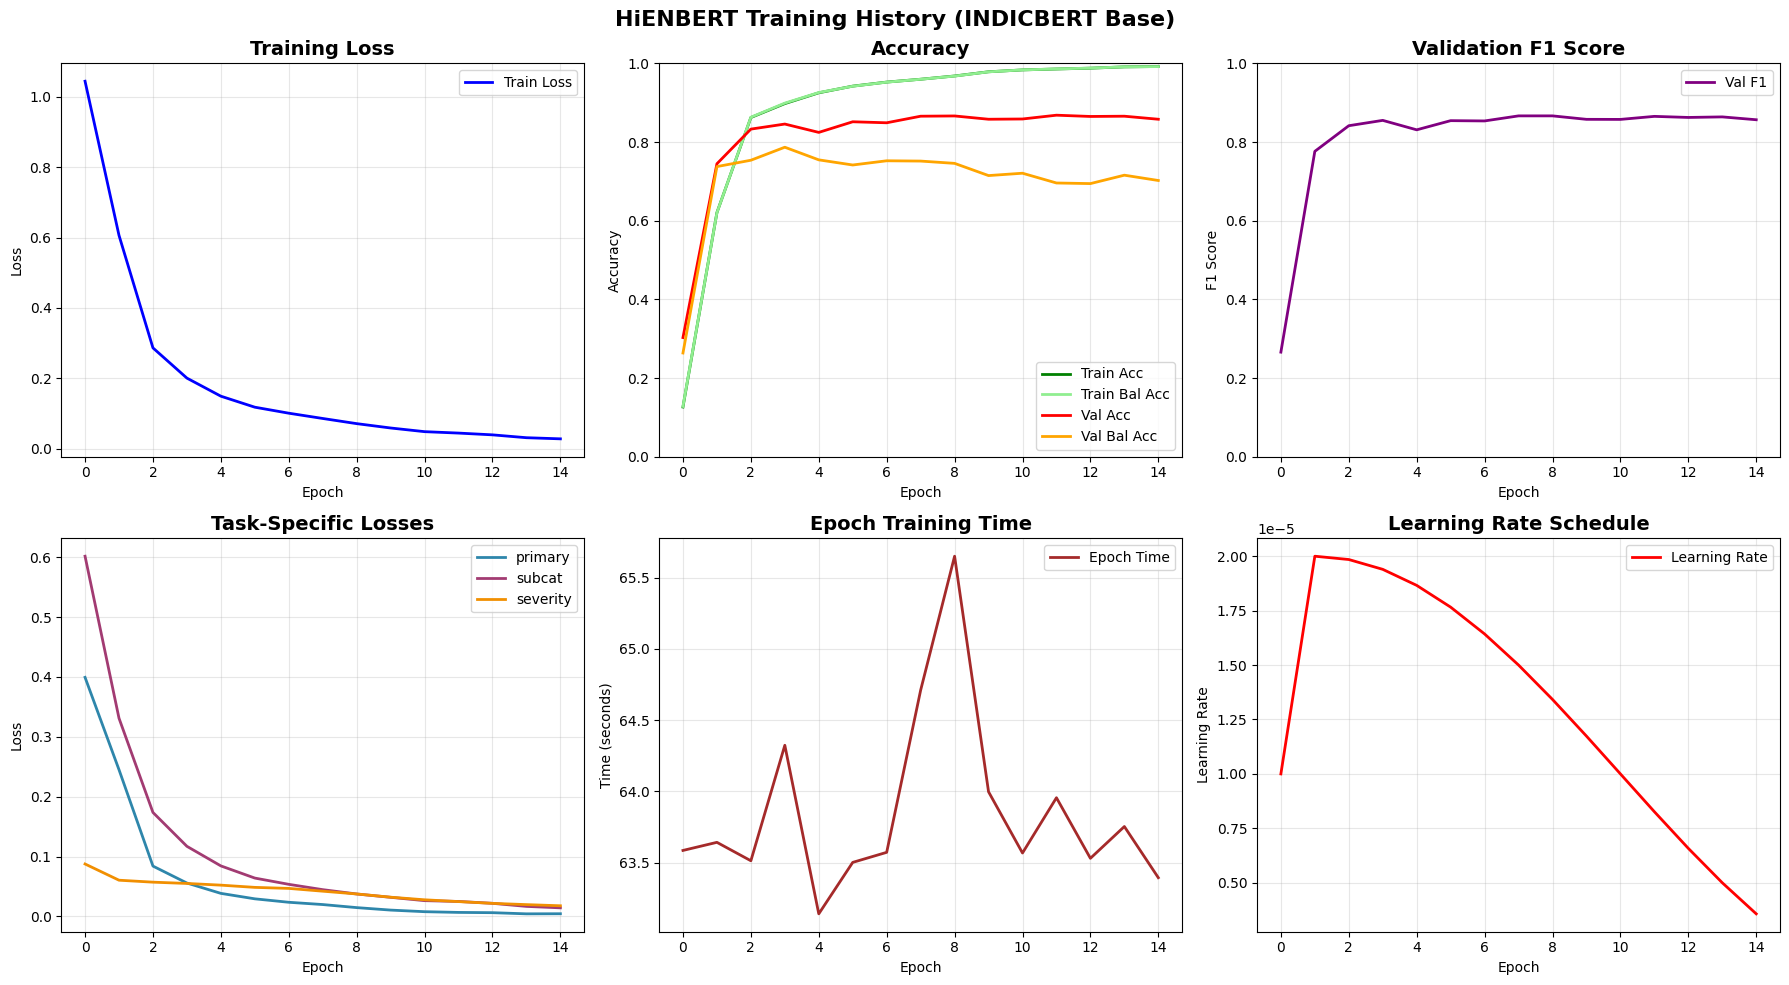

In [15]:
# ============================================================================
# CELL 13: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_training_history(train_history, val_history, save_path=None):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2, color='blue')
    axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Training accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2, color='green')
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2, color='lightgreen')
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2, color='red')
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2, color='orange')
    axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_ylim(0, 1)
    
    # Validation F1
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score', fontsize=14, fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('F1 Score')
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    axes[0, 2].set_ylim(0, 1)
    
    # Task-specific losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task-Specific Losses', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    times = [h.get('time', 0) for h in train_history]
    axes[1, 1].plot(times, label='Epoch Time', linewidth=2, color='brown')
    axes[1, 1].set_title('Epoch Training Time', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Time (seconds)')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    lrs = [h.get('lr', 0) for h in train_history]
    axes[1, 2].plot(lrs, label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 2].set_xlabel('Epoch')
    axes[1, 2].set_ylabel('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot training history
plot_training_history(
    train_history, val_history,
    save_path=f"{Config.VISUALIZATION_DIR}/training_history.png"
)

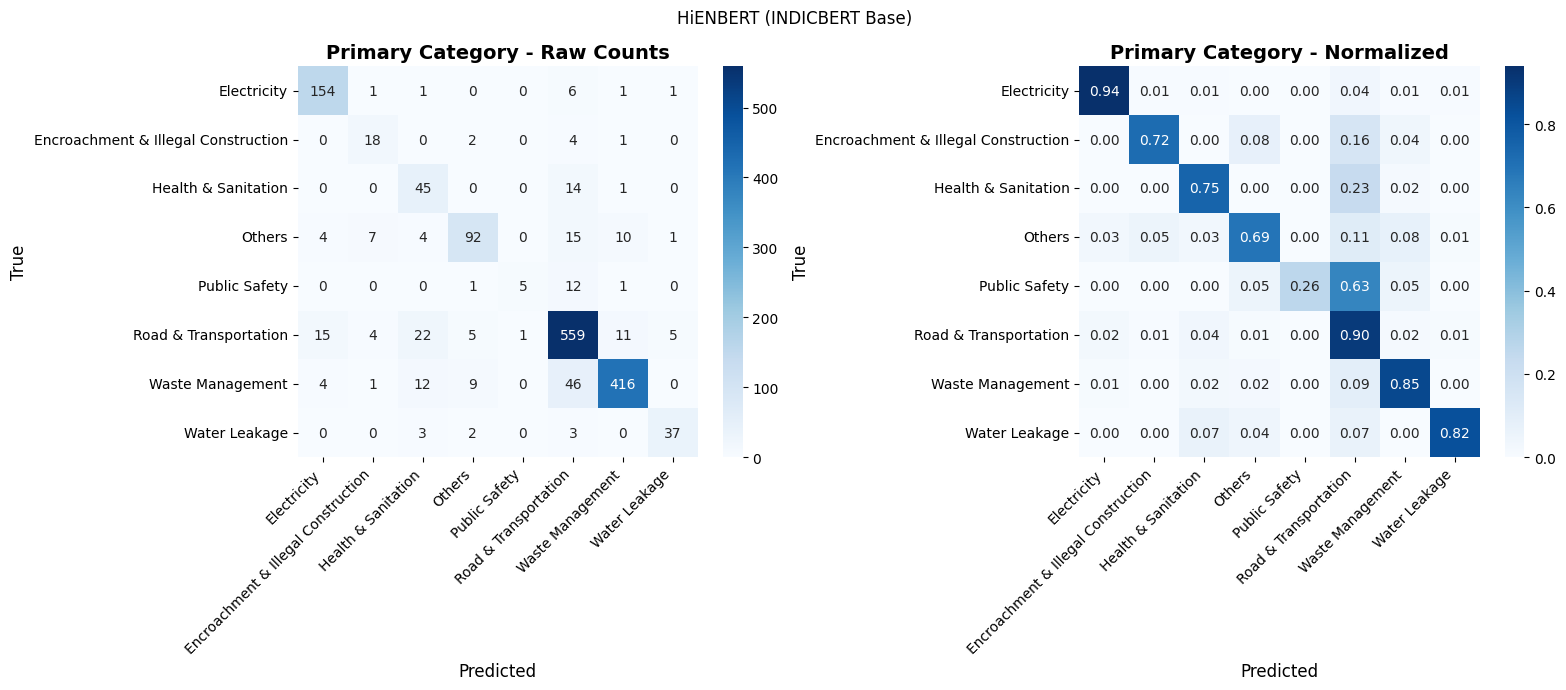

Getting severity predictions: 100%|██████████| 25/25 [00:05<00:00,  4.63it/s]


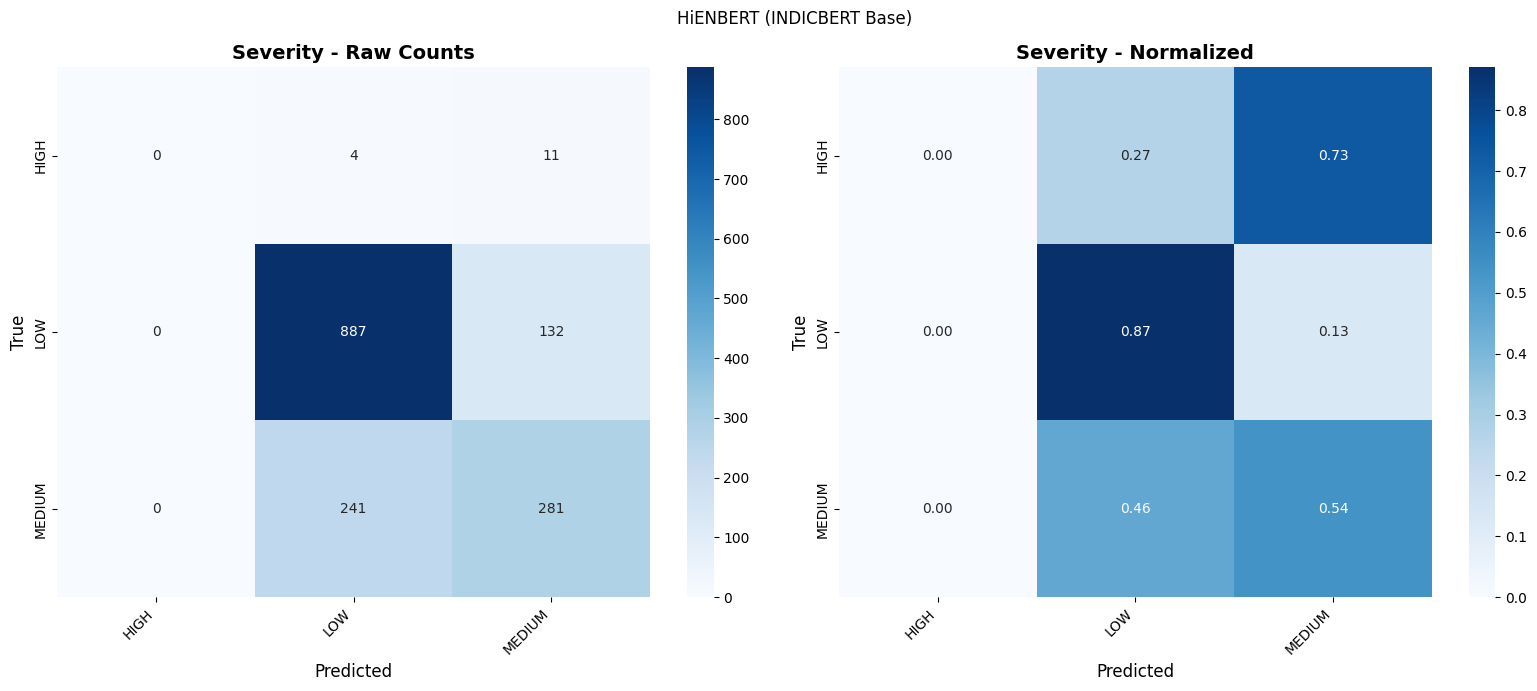

✅ Confusion matrices saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\visualizations


In [18]:
# ============================================================================
# CELL 14: CONFUSION MATRIX VISUALIZATIONS
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    """Plot confusion matrix with raw and normalized versions"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted', fontsize=12)
    axes[0].set_ylabel('True', fontsize=12)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted', fontsize=12)
    axes[1].set_ylabel('True', fontsize=12)
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrices
class_names = preprocessor.le_primary.classes_

plot_confusion_matrix(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

# Get severity predictions for confusion matrix
model.eval()
severity_preds = []
severity_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Getting severity predictions"):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        sentiment = batch['sentiment'].to(Config.DEVICE)
        
        _, _, p3 = model(input_ids, attention_mask, sentiment)
        preds = torch.argmax(p3, dim=1)
        severity_preds.extend(preds.cpu().numpy())
        severity_labels.extend(batch['severity'].cpu().numpy())

severity_names = preprocessor.le_severity.classes_

plot_confusion_matrix(
    severity_labels, severity_preds, severity_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_severity.png"
)

print(f"✅ Confusion matrices saved to: {Config.VISUALIZATION_DIR}")

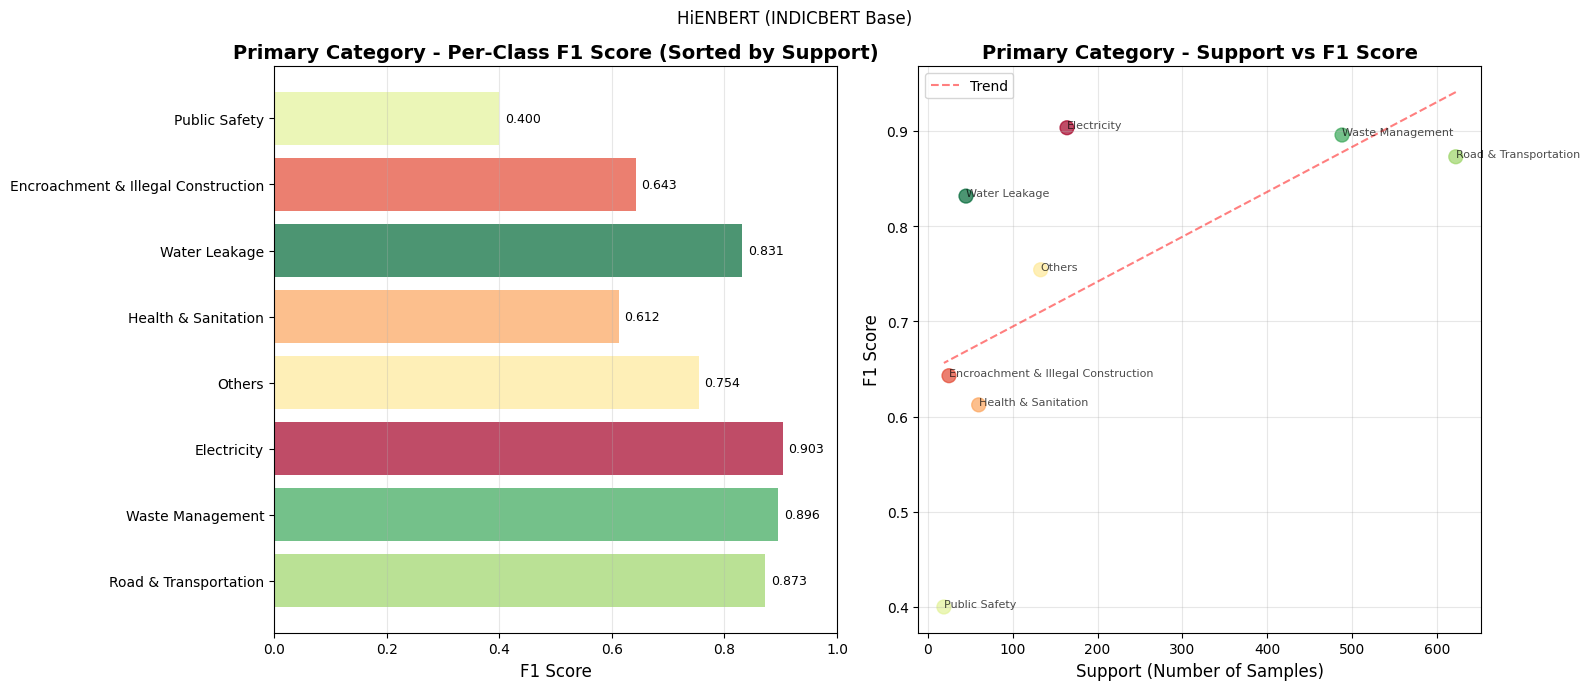

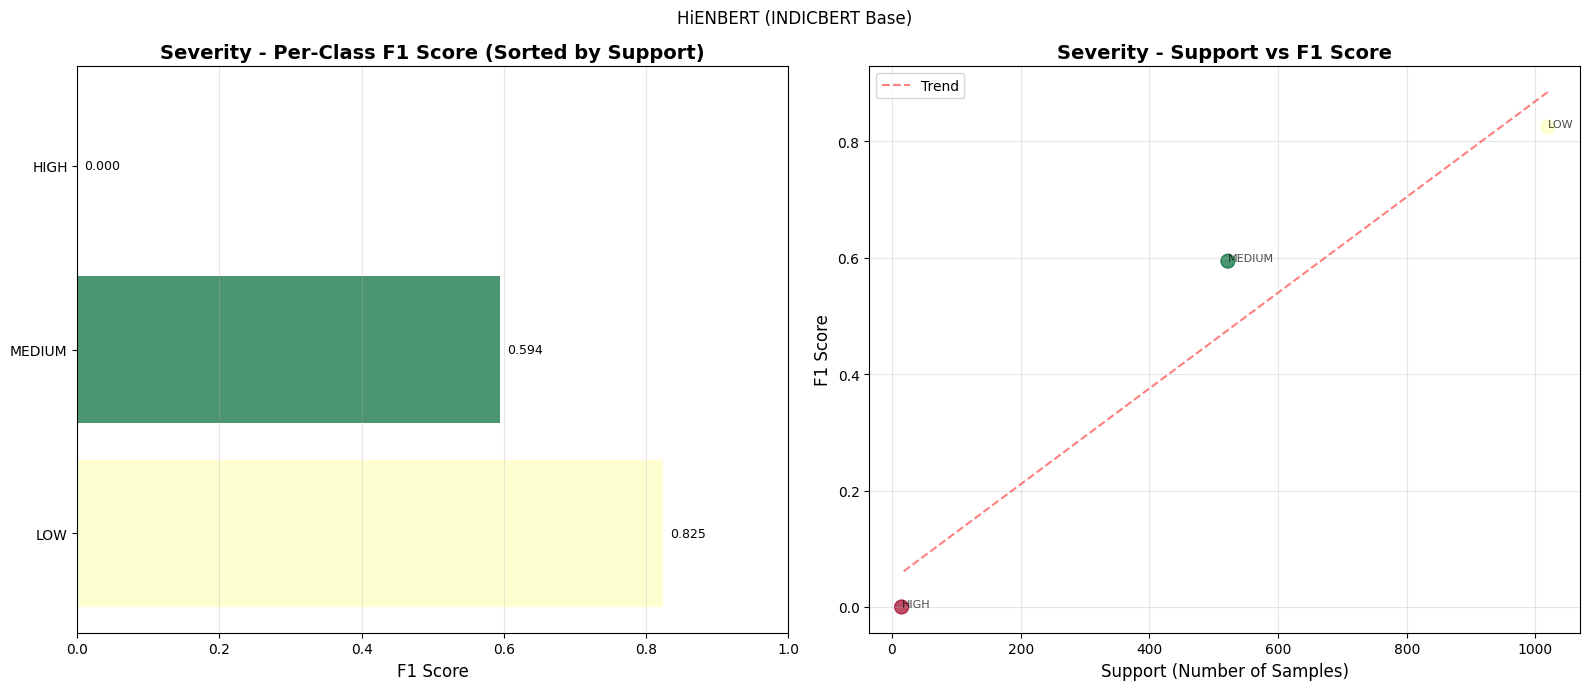

In [19]:
# ============================================================================
# CELL 15: PER-CLASS PERFORMANCE VISUALIZATION
# ============================================================================

def plot_per_class_performance(y_true, y_pred, class_names, title, save_path=None):
    """Visualize per-class performance metrics"""
    
    from sklearn.metrics import precision_recall_fscore_support
    
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, average=None
    )
    
    sorted_indices = np.argsort(support)[::-1]
    class_names_sorted = [class_names[i] for i in sorted_indices]
    precision_sorted = [precision[i] for i in sorted_indices]
    recall_sorted = [recall[i] for i in sorted_indices]
    f1_sorted = [f1[i] for i in sorted_indices]
    support_sorted = [support[i] for i in sorted_indices]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # F1 scores
    colors = plt.cm.RdYlGn(np.linspace(0, 1, len(class_names)))[sorted_indices]
    bars = axes[0].barh(range(len(class_names)), f1_sorted, color=colors, alpha=0.7)
    axes[0].set_yticks(range(len(class_names)))
    axes[0].set_yticklabels(class_names_sorted, fontsize=10)
    axes[0].set_xlabel('F1 Score', fontsize=12)
    axes[0].set_title(f'{title} - Per-Class F1 Score (Sorted by Support)', fontsize=14, fontweight='bold')
    axes[0].set_xlim(0, 1)
    axes[0].grid(True, alpha=0.3, axis='x')
    
    for bar, val in zip(bars, f1_sorted):
        axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                    f'{val:.3f}', va='center', fontsize=9)
    
    # Support vs F1 scatter
    axes[1].scatter(support_sorted, f1_sorted, alpha=0.7, s=100, c=colors)
    axes[1].set_xlabel('Support (Number of Samples)', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title(f'{title} - Support vs F1 Score', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    # Add trend line
    z = np.polyfit(support_sorted, f1_sorted, 1)
    p = np.poly1d(z)
    axes[1].plot(support_sorted, p(support_sorted), "r--", alpha=0.5, label='Trend')
    
    # Annotate points with class names
    for i, (x, y, name) in enumerate(zip(support_sorted, f1_sorted, class_names_sorted)):
        axes[1].annotate(name, (x, y), fontsize=8, alpha=0.7)
    
    axes[1].legend()
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot per-class performance
plot_per_class_performance(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/per_class_performance.png"
)

# Severity per-class performance
plot_per_class_performance(
    severity_labels, severity_preds, severity_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/severity_per_class_performance.png"
)

Extracting embeddings for t-SNE...


Extracting embeddings: 100%|██████████| 25/25 [00:08<00:00,  2.88it/s]


Extracted 1556 embeddings of dimension 768
Applying t-SNE...


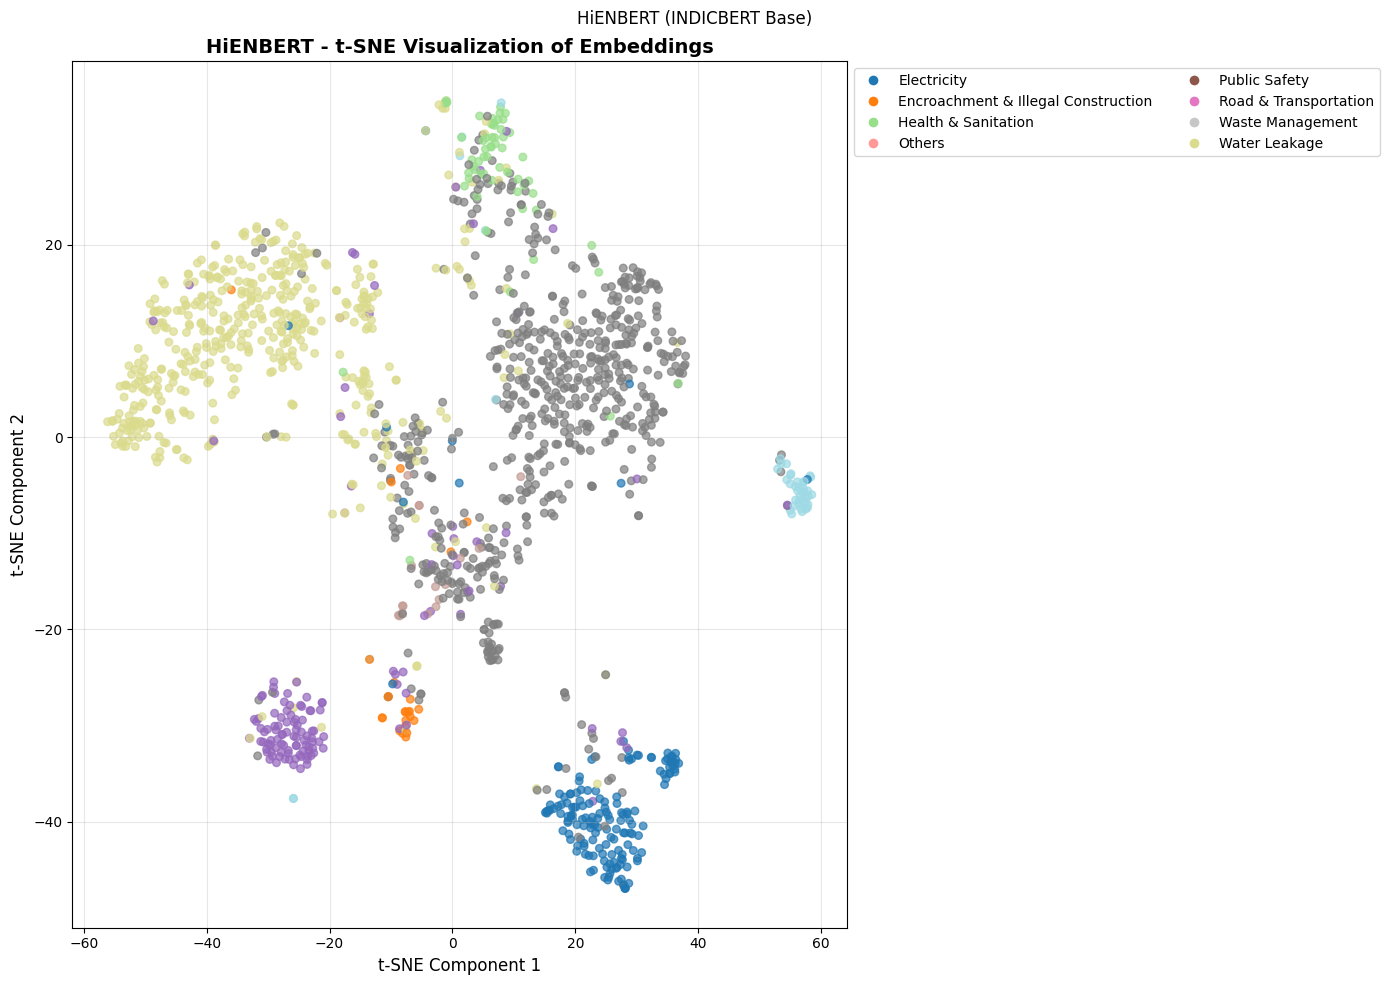

array([[ 26.229574  ,   8.57707   ],
       [ -6.9890614 , -28.509827  ],
       [-44.789818  ,  13.167509  ],
       ...,
       [-15.8135195 ,  -0.73692775],
       [-22.811632  , -30.574226  ],
       [-43.703526  ,  -2.1561413 ]], shape=(1556, 2), dtype=float32)

In [20]:
# ============================================================================
# CELL 16: T-SNE EMBEDDING VISUALIZATION
# ============================================================================

def plot_tsne_embeddings(model, test_loader, class_names, device, title, save_path=None):
    """Create t-SNE visualization of embeddings"""
    print("Extracting embeddings for t-SNE...")
    
    model.eval()
    embeddings = []
    labels = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Extracting embeddings"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            _, _, _ = model(input_ids, attention_mask, sentiment)
            outputs = model.base(input_ids=input_ids, attention_mask=attention_mask)
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())
            labels.extend(batch['primary'].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    labels = np.array(labels)
    
    print(f"Extracted {embeddings.shape[0]} embeddings of dimension {embeddings.shape[1]}")
    
    # Sample if too many points for t-SNE
    if len(embeddings) > 2000:
        idx = np.random.choice(len(embeddings), 2000, replace=False)
        embeddings = embeddings[idx]
        labels = labels[idx]
    
    # Apply t-SNE
    print("Applying t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, verbose=0)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(14, 10))
    
    scatter = ax.scatter(
        embeddings_2d[:, 0], embeddings_2d[:, 1],
        c=labels, cmap='tab20', alpha=0.7, s=30
    )
    
    ax.set_xlabel('t-SNE Component 1', fontsize=12)
    ax.set_ylabel('t-SNE Component 2', fontsize=12)
    ax.set_title(f'{title} - t-SNE Visualization of Embeddings', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add legend
    legend_elements = []
    for i, name in enumerate(class_names):
        if i < len(plt.cm.tab20.colors):
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=plt.cm.tab20(i/len(class_names)),
                          label=name, markersize=8)
            )
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), ncol=2)
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return embeddings_2d

# Generate t-SNE visualization
plot_tsne_embeddings(
    model, test_loader, class_names, Config.DEVICE,
    'HiENBERT',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png"
)

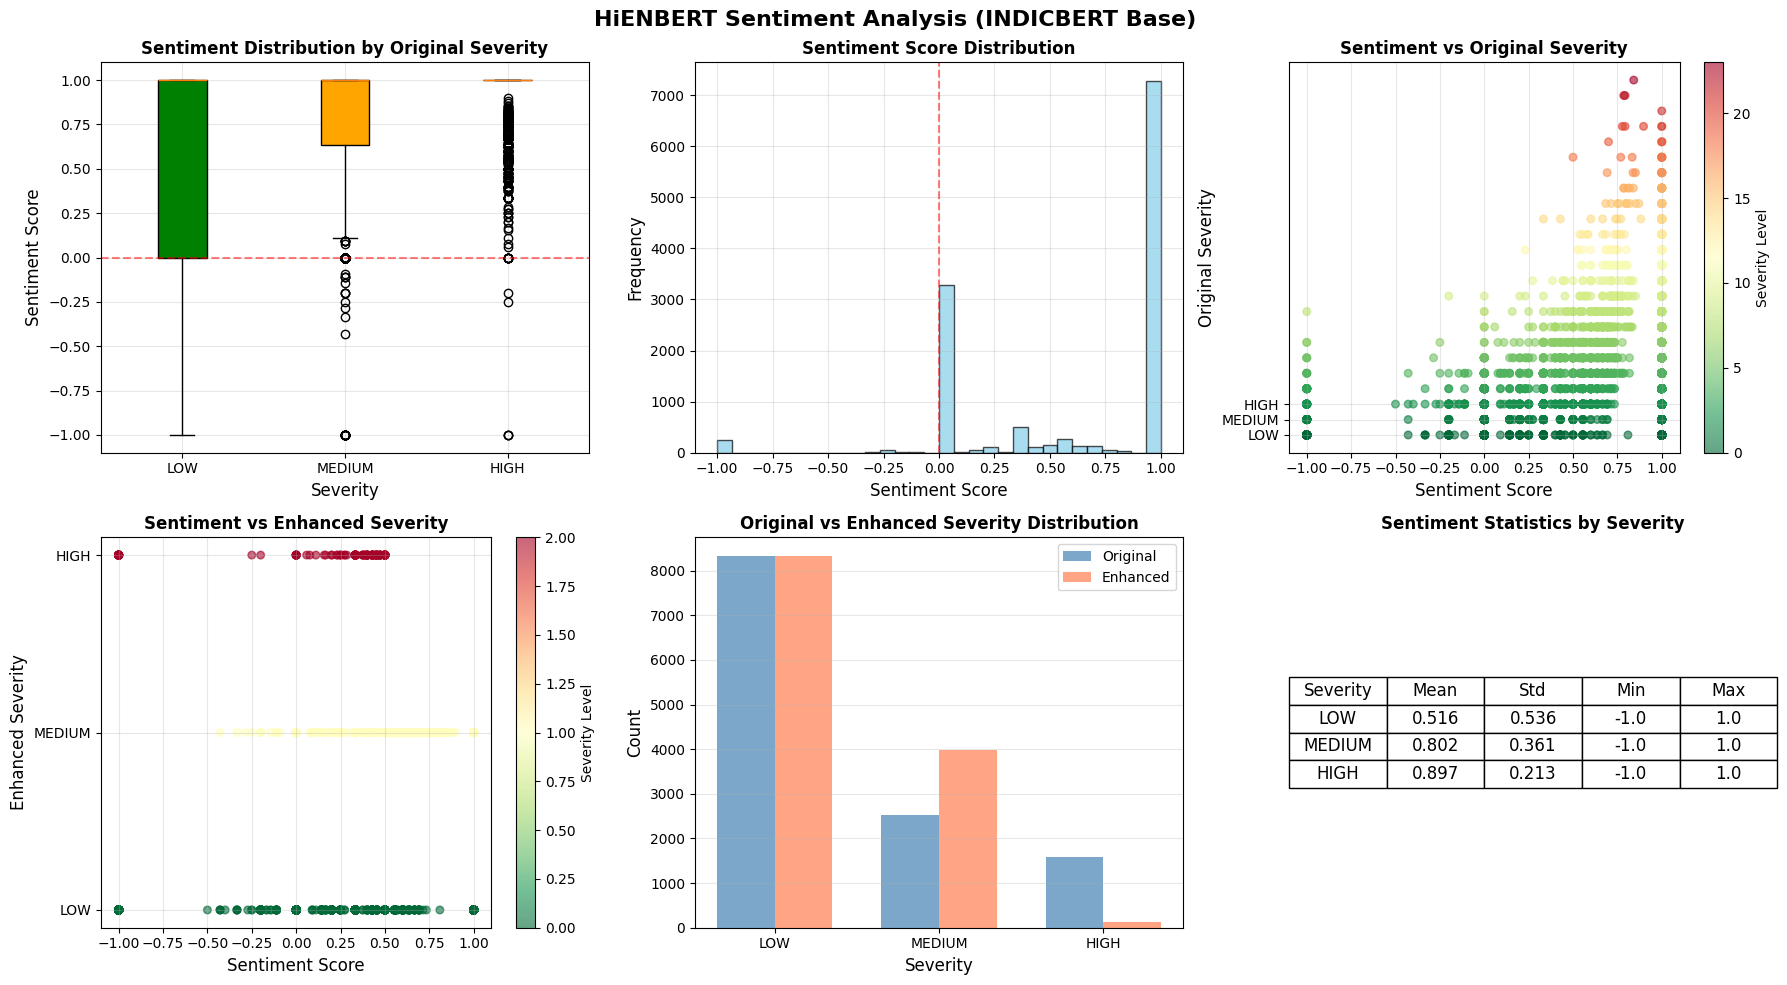

✅ Sentiment analysis saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\visualizations/sentiment_analysis.png


In [21]:
# ============================================================================
# CELL 17: SENTIMENT ANALYSIS VISUALIZATION
# ============================================================================

def plot_sentiment_analysis(df, save_path=None):
    """Analyze and visualize sentiment patterns"""
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']
    
    # 1. Sentiment distribution by severity
    sentiment_by_severity = [
        df[df['severity'] == s]['sentiment_score'].values 
        for s in severity_order
    ]
    
    bp = axes[0, 0].boxplot(sentiment_by_severity, labels=severity_order, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 0].set_xlabel('Severity', fontsize=12)
    axes[0, 0].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 0].set_title('Sentiment Distribution by Original Severity', fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Sentiment distribution histogram
    axes[0, 1].hist(df['sentiment_score'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    axes[0, 1].axvline(x=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 1].set_xlabel('Sentiment Score', fontsize=12)
    axes[0, 1].set_ylabel('Frequency', fontsize=12)
    axes[0, 1].set_title('Sentiment Score Distribution', fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Sentiment vs Severity Scatter (Original)
    scatter = axes[0, 2].scatter(
    df['sentiment_score'],
    df['severity_score'],
    c=df['severity_score'],
    cmap='RdYlGn_r',
    alpha=0.6,
    s=30
)
    axes[0, 2].set_xlabel('Sentiment Score', fontsize=12)
    axes[0, 2].set_ylabel('Original Severity', fontsize=12)
    axes[0, 2].set_yticks([0, 1, 2])
    axes[0, 2].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
    axes[0, 2].set_title('Sentiment vs Original Severity', fontweight='bold')
    axes[0, 2].grid(True, alpha=0.3)
    plt.colorbar(scatter, label='Severity Level', ax=axes[0, 2])
    
    # 4. Sentiment vs Enhanced Severity Scatter
    if 'enhanced_severity' in df.columns:
        scatter = axes[1, 0].scatter(
            df['sentiment_score'], 
            df['enhanced_severity'],
            c=df['enhanced_severity'],
            cmap='RdYlGn_r',
            alpha=0.6,
            s=30
        )
        axes[1, 0].set_xlabel('Sentiment Score', fontsize=12)
        axes[1, 0].set_ylabel('Enhanced Severity', fontsize=12)
        axes[1, 0].set_yticks([0, 1, 2])
        axes[1, 0].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
        axes[1, 0].set_title('Sentiment vs Enhanced Severity', fontweight='bold')
        axes[1, 0].grid(True, alpha=0.3)
        plt.colorbar(scatter, label='Severity Level', ax=axes[1, 0])
    
    # 5. Severity Distribution Comparison
    original_counts = df['severity'].value_counts()
    enhanced_counts = df['enhanced_severity_label'].value_counts() if 'enhanced_severity_label' in df.columns else original_counts
    
    x = np.arange(len(severity_order))
    width = 0.35
    
    bars1 = axes[1, 1].bar(x - width/2, 
                          [original_counts.get(s, 0) for s in severity_order], 
                          width, label='Original', color='steelblue', alpha=0.7)
    bars2 = axes[1, 1].bar(x + width/2, 
                          [enhanced_counts.get(s, 0) for s in severity_order], 
                          width, label='Enhanced', color='coral', alpha=0.7)
    
    axes[1, 1].set_xlabel('Severity', fontsize=12)
    axes[1, 1].set_ylabel('Count', fontsize=12)
    axes[1, 1].set_title('Original vs Enhanced Severity Distribution', fontweight='bold')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(severity_order)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')
    
    # 6. Sentiment statistics by severity
    stats_data = []
    for severity in severity_order:
        scores = df[df['severity'] == severity]['sentiment_score']
        stats_data.append([
            severity,
            scores.mean(),
            scores.std(),
            scores.min(),
            scores.max()
        ])
    
    stats_df = pd.DataFrame(stats_data, columns=['Severity', 'Mean', 'Std', 'Min', 'Max'])
    axes[1, 2].axis('tight')
    axes[1, 2].axis('off')
    table = axes[1, 2].table(cellText=stats_df.round(3).values,
                            colLabels=stats_df.columns,
                            cellLoc='center',
                            loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.5)
    axes[1, 2].set_title('Sentiment Statistics by Severity', fontweight='bold')
    
    plt.suptitle(f'HiENBERT Sentiment Analysis ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot sentiment analysis
plot_sentiment_analysis(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/sentiment_analysis.png"
)

print(f"✅ Sentiment analysis saved to: {Config.VISUALIZATION_DIR}/sentiment_analysis.png")

In [22]:
print(train_df.columns.tolist())

['original_id', 'Complain_date', 'complaint_title', 'text_en', 'location_address', 'category_primary', 'category_secondary', 'resolution_status', 'comment_count', 'Hindi', 'Hinglish', 'severity', 'severity_score', 'high_keywords_matched', 'medium_keywords_matched', 'text', 'sentiment_score', 'enhanced_severity', 'enhanced_severity_label', 'primary_label', 'subcat_label', 'severity_label']


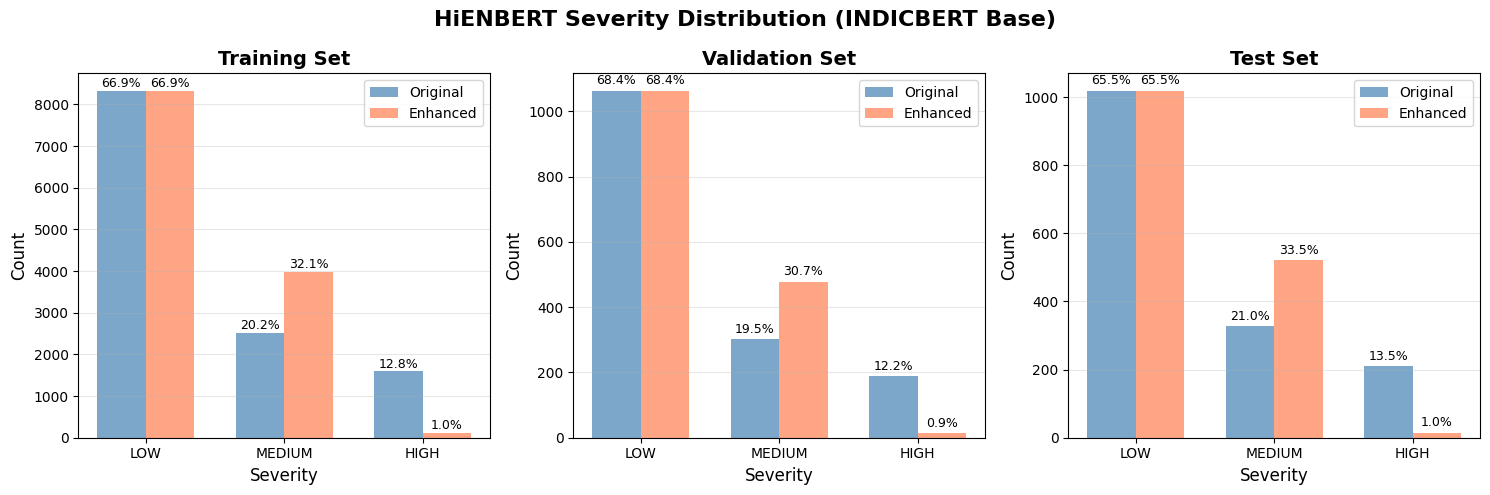

✅ Severity distribution saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\visualizations/severity_distribution.png


In [23]:
# ============================================================================
# CELL 18: SEVERITY DISTRIBUTION VISUALIZATION
# ============================================================================

def plot_severity_distribution(train_df, dev_df, test_df, save_path=None):
    """Visualize severity distribution across datasets"""
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']
    
    datasets = [
        ('Training', train_df),
        ('Validation', dev_df),
        ('Test', test_df)
    ]
    
    for ax, (name, df) in zip(axes, datasets):
        # Original severity
        original_counts = df['severity'].value_counts()
        original_pcts = df['severity'].value_counts(normalize=True) * 100
        
        # Enhanced severity (if available)
        if 'enhanced_severity_label' in df.columns:
            enhanced_counts = df['enhanced_severity_label'].value_counts()
            enhanced_pcts = df['enhanced_severity_label'].value_counts(normalize=True) * 100
        else:
            enhanced_counts = original_counts
            enhanced_pcts = original_pcts
        
        # Create grouped bar chart
        x = np.arange(len(severity_order))
        width = 0.35
        
        bars1 = ax.bar(x - width/2, 
                      [original_counts.get(s, 0) for s in severity_order], 
                      width, label='Original', color='steelblue', alpha=0.7)
        bars2 = ax.bar(x + width/2, 
                      [enhanced_counts.get(s, 0) for s in severity_order], 
                      width, label='Enhanced', color='coral', alpha=0.7)
        
        ax.set_xlabel('Severity', fontsize=12)
        ax.set_ylabel('Count', fontsize=12)
        ax.set_title(f'{name} Set', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(severity_order)
        ax.legend()
        ax.grid(True, alpha=0.3, axis='y')
        
        # Add percentage labels
        for bar, pct in zip(bars1, [original_pcts.get(s, 0) for s in severity_order]):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 10,
                   f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)
        
        for bar, pct in zip(bars2, [enhanced_pcts.get(s, 0) for s in severity_order]):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 10,
                   f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)
    
    plt.suptitle(f'HiENBERT Severity Distribution ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot severity distribution
plot_severity_distribution(
    train_df, dev_df, test_df,
    save_path=f"{Config.VISUALIZATION_DIR}/severity_distribution.png"
)

print(f"✅ Severity distribution saved to: {Config.VISUALIZATION_DIR}/severity_distribution.png")

In [24]:
# ============================================================================
# CELL 19: MODEL COMPARISON SUMMARY
# ============================================================================

def generate_model_comparison(test_metrics, best_val_f1, save_path=None):
    """Generate model comparison summary for IEEE Access paper"""
    
    print("\n" + "="*80)
    print("HIENBERT MODEL COMPARISON SUMMARY")
    print("="*80)
    
    print(f"\nBase Model: {Config.BASE_MODEL.upper()}")
    print(f"Model Path: {get_model_path()}")
    
    print("\n1. PERFORMANCE METRICS (Test Set):")
    print("-"*50)
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"  {metric}: {value:.4f}")
    
    print(f"\n2. BEST VALIDATION PERFORMANCE:")
    print(f"  Best Validation F1: {best_val_f1:.4f}")
    print(f"  Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    print(f"\n3. MODEL STATISTICS:")
    print(f"  Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"  Trainable Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    print(f"  Hidden Size: {model.hidden_size}")
    print(f"  Dropout Rate: {Config.DROPOUT}")
    print(f"  Max Sequence Length: {Config.MAX_LENGTH}")
    
    print(f"\n4. IMBALANCE HANDLING:")
    print(f"  Class Weights: {Config.USE_CLASS_WEIGHTS}")
    print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
    if Config.USE_FOCAL_LOSS:
        print(f"  Focal Alpha: {Config.FOCAL_ALPHA}")
        print(f"  Focal Gamma: {Config.FOCAL_GAMMA}")
    print(f"  Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    print(f"\n5. TRAINING SETTINGS:")
    print(f"  Epochs: {Config.EPOCHS}")
    print(f"  Batch Size: {Config.BATCH_SIZE}")
    print(f"  Learning Rate: {Config.LEARNING_RATE}")
    print(f"  Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"  Mixed Precision: {Config.USE_AMP}")
    
    # Create comparison table
    comparison_data = {
        'Metric': ['Accuracy', 'Balanced Accuracy', 'F1-Macro', 'F1-Weighted', 
                  'Precision', 'Recall', 'Cohen\'s Kappa', 'Matthews CC'],
        'Value': [
            test_metrics['accuracy'],
            test_metrics['balanced_accuracy'],
            test_metrics['f1_macro'],
            test_metrics['f1_weighted'],
            test_metrics['precision'],
            test_metrics['recall'],
            test_metrics['cohen_kappa'],
            test_metrics['mcc']
        ]
    }
    
    comparison_df = pd.DataFrame(comparison_data)
    print("\n6. COMPARISON TABLE:")
    print(comparison_df.to_string(index=False))
    
    # Save to CSV
    comparison_df.to_csv(f"{Config.RESULTS_DIR}/model_comparison.csv", index=False)
    print(f"\n✅ Comparison table saved to: {Config.RESULTS_DIR}/model_comparison.csv")
    
    return comparison_df

# Generate comparison summary
comparison_df = generate_model_comparison(test_metrics, best_val_f1)


HIENBERT MODEL COMPARISON SUMMARY

Base Model: INDICBERT
Model Path: ai4bharat/indic-bert

1. PERFORMANCE METRICS (Test Set):
--------------------------------------------------
  accuracy: 0.8522
  balanced_accuracy: 0.7422
  f1_macro: 0.7390
  f1_weighted: 0.8523
  precision: 0.8612
  recall: 0.8522
  cohen_kappa: 0.7948
  mcc: 0.7960

2. BEST VALIDATION PERFORMANCE:
  Best Validation F1: 0.8664
  Best Validation Balanced Accuracy: 0.7457

3. MODEL STATISTICS:
  Total Parameters: 34,063,401
  Trainable Parameters: 34,063,401
  Hidden Size: 768
  Dropout Rate: 0.3
  Max Sequence Length: 128

4. IMBALANCE HANDLING:
  Class Weights: True
  Focal Loss: True
  Focal Alpha: 0.25
  Focal Gamma: 2.0
  Weighted Sampler: True

5. TRAINING SETTINGS:
  Epochs: 20
  Batch Size: 32
  Learning Rate: 2e-05
  Weight Decay: 0.01
  Mixed Precision: True

6. COMPARISON TABLE:
           Metric    Value
         Accuracy 0.852185
Balanced Accuracy 0.742163
         F1-Macro 0.739029
      F1-Weighted 0.8

In [25]:
# ============================================================================
# CELL 20: COMPLETE SUMMARY REPORT
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.BASE_MODEL.upper()}")
    print(f"   Model Path: {get_model_path()}")
    print(f"   Hidden Size: {model.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # 3. Imbalance Handling
    print("\n3. IMBALANCE HANDLING:")
    print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    if Config.USE_FOCAL_LOSS:
        print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
        print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Mixed Precision: {Config.USE_AMP}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Best Validation Performance
    print("\n6. BEST VALIDATION PERFORMANCE:")
    print(f"   Best Validation F1: {best_val_f1:.4f}")
    print(f"   Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    # 7. Training History
    print("\n7. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Final Train Balanced Accuracy: {train_history[-1]['balanced_acc']:.4f}")
    
    # 8. Severity Distribution
    print("\n8. SEVERITY DISTRIBUTION (Training):")
    severity_dist = train_df['severity'].value_counts()
    severity_pct = train_df['severity'].value_counts(normalize=True) * 100
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        print(f"   {severity}: {severity_dist.get(severity, 0)} ({severity_pct.get(severity, 0):.1f}%)")
    
    # 9. Saved Files
    print("\n9. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_hienbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/hienbert_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Test Results: {Config.RESULTS_DIR}/test_results.json")
    print(f"   Comparison Table: {Config.RESULTS_DIR}/model_comparison.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        f.write(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)\n")
        f.write("="*80 + "\n\n")
        # Write all the above information to file
        # ... (similar content as printed)

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")
print(f"\n{'='*80}")
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)


HIENBERT COMPREHENSIVE SUMMARY REPORT (INDICBERT Base)

1. DATASET STATISTICS:
   Training samples: 12441
   Validation samples: 1555
   Test samples: 1556
   Primary categories: 8
   Subcategories: 27
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: INDICBERT
   Model Path: ai4bharat/indic-bert
   Hidden Size: 768
   Total Parameters: 34,063,401
   Dropout Rate: 0.3
   Max Sequence Length: 128

3. IMBALANCE HANDLING:
   Class Weights: True
   Focal Loss: True
   Focal Alpha: 0.25
   Focal Gamma: 2.0
   Weighted Sampler: True

4. TRAINING DETAILS:
   Epochs: 20
   Batch Size: 32
   Learning Rate: 2e-05
   Weight Decay: 0.01
   Mixed Precision: True

5. TEST SET PERFORMANCE:
   accuracy: 0.8522
   balanced_accuracy: 0.7422
   f1_macro: 0.7390
   f1_weighted: 0.8523
   precision: 0.8612
   recall: 0.8522
   cohen_kappa: 0.7948
   mcc: 0.7960

6. BEST VALIDATION PERFORMANCE:
   Best Validation F1: 0.8664
   Best Validation Balanced Accuracy: 0.7457

7. TRAINING HISTORY:
   Fi


STARTING ABLATION STUDY

Creating datasets and dataloaders...
Using WeightedRandomSampler for balanced batches...
Train batches: 389
Dev batches: 25
Test batches: 25

Verifying test dataset...
  Batch size: 32
  Input shape: torch.Size([32, 128])
  Labels shape: torch.Size([32])
  Sentiment shape: torch.Size([32])
Loading base model: ai4bharat/indic-bert
Model type: indicbert


Loading weights: 100%|██████████| 25/25 [00:00<00:00, 11771.17it/s]
[transformers] AlbertModel LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     |  | 
---------------------------------+------------+--+-
sop_classifier.classifier.weight | UNEXPECTED |  | 
predictions.bias                 | UNEXPECTED |  | 
predictions.LayerNorm.weight     | UNEXPECTED |  | 
predictions.decoder.weight       | UNEXPECTED |  | 
predictions.LayerNorm.bias       | UNEXPECTED |  | 
predictions.dense.bias           | UNEXPECTED |  | 
predictions.dense.weight         | UNEXPECTED |  | 
sop_classifier.classifier.bias   | UNEXPECTED |  | 
predictions.decoder.bias         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocabulary size: 200000
Hidden size: 768

STARTING COMPLETE ABLATION STUDY

BASELINE: Full Model

  Accuracy: 0.9764
  F1 (Weighted): 0.9763

TEST: Sentiment Enhancement

1. With Sentiment Enhancement (Baseline)
  F1: 0.9763

2. Without Sentiment Enhancement
  Shape mismatch for fc_severity.weight: torch.Size([3, 769]) vs torch.Size([3, 768])
  F1: 0.9783

TEST: Shared Layer

1. With Shared Layer (Baseline)
  F1: 0.9762

2. Without Shared Layer
  F1: 0.1322

TEST: Dropout Rate

0.1. Dropout 0.1
  F1: 0.9762

0.3. Dropout 0.3
  F1: 0.9775

0.5. Dropout 0.5
  F1: 0.9768

TEST: Task Weights

1. Equal Weights (Baseline)
  F1: 0.9791

2. Primary Task Weighted (2x)
  F1: 0.9796

ABLATION STUDY COMPLETED in 435.15 seconds

ABLATION STUDY RESULTS

Configuration                  Accuracy     F1 (Weighted)   Bal Acc     
----------------------------------------------------------------------
baseline                       0.9764     0.9763       0.9768
with_sentiment                 0.9764     0.

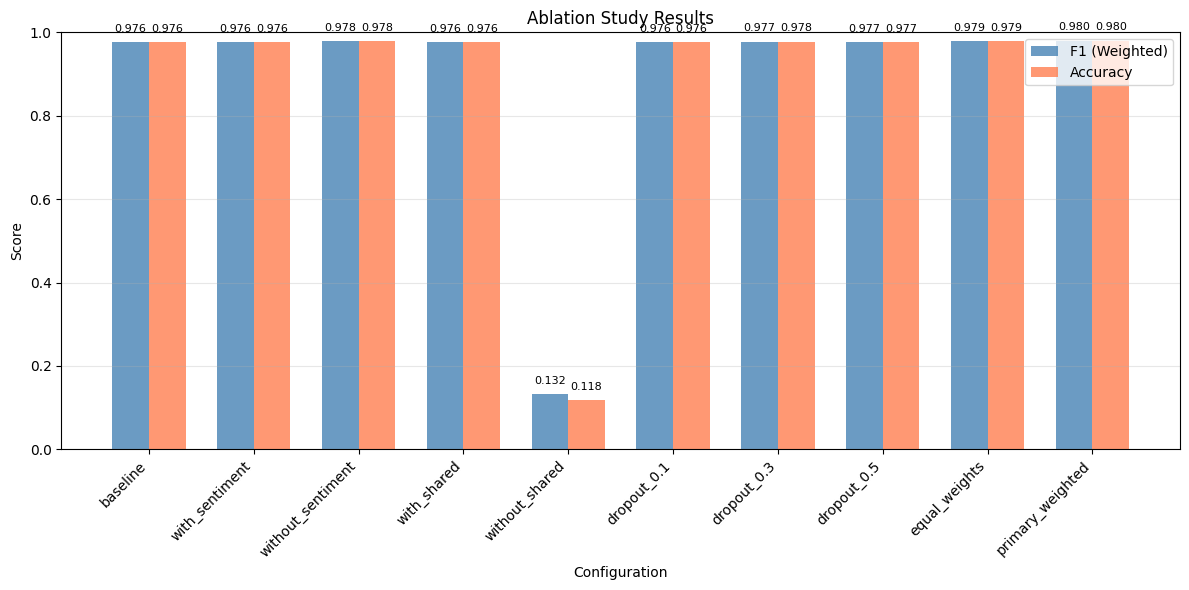


✅ Ablation study results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\BERT_Project_Backup\Original Dataset\HiENBERT\hienbert_indicbert_results\visualizations/ablation_study_results.png


In [32]:
# ============================================================================
# CELL 21: CORRECTED ABLATION STUDY
# ============================================================================

import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

class HiEnBERTBase(nn.Module):
    """Original HiENBERT model"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        self.shared_layer = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size + 1, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        if sentiment is not None:
            sentiment = sentiment.unsqueeze(1)
            severity_input = torch.cat([x, sentiment], dim=1)
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTNoSentiment(HiEnBERTBase):
    """HiENBERT without sentiment enhancement"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__(base_model, n_primary, n_subcat, n_severity, dropout)
        # Override severity head
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTNoShared(HiEnBERTBase):
    """HiENBERT without shared layer"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__(base_model, n_primary, n_subcat, n_severity, dropout)
        self.shared_layer = nn.Identity()
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.dropout(cls_embedding)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        if sentiment is not None:
            sentiment = sentiment.unsqueeze(1)
            severity_input = torch.cat([x, sentiment], dim=1)
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTDropout(HiEnBERTBase):
    """HiENBERT with configurable dropout"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__(base_model, n_primary, n_subcat, n_severity, dropout)
        self.dropout = nn.Dropout(dropout)
        # Recreate shared layer with new dropout
        self.shared_layer = nn.Sequential(
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )


class HiEnBERTTaskWeighted(HiEnBERTBase):
    """HiENBERT with task-specific weights"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3, 
                 primary_weight=2.0, subcat_weight=1.0, severity_weight=0.5):
        super().__init__(base_model, n_primary, n_subcat, n_severity, dropout)
        self.primary_weight = primary_weight
        self.subcat_weight = subcat_weight
        self.severity_weight = severity_weight


def evaluate_ablation(model, test_loader, device):
    """Evaluate model and return metrics"""
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            labels = batch['primary'].to(device)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    return {'accuracy': acc, 'f1_weighted': f1, 'balanced_accuracy': bal_acc}


def transfer_weights(source_model, target_model):
    """Transfer weights from source to target model where possible"""
    source_dict = source_model.state_dict()
    target_dict = target_model.state_dict()
    
    # Find common keys
    common_keys = set(source_dict.keys()) & set(target_dict.keys())
    
    # Transfer weights for common keys
    for key in common_keys:
        if source_dict[key].shape == target_dict[key].shape:
            target_dict[key] = source_dict[key].clone()
        else:
            print(f"  Shape mismatch for {key}: {source_dict[key].shape} vs {target_dict[key].shape}")
    
    target_model.load_state_dict(target_dict, strict=False)
    return target_model


def run_ablation_study(model, base_model, test_loader, device, preprocessor):
    """Run complete ablation study"""
    
    print("\n" + "="*80)
    print("STARTING COMPLETE ABLATION STUDY")
    print("="*80)
    
    results = {}
    
    # Get base model architecture
    n_primary = len(preprocessor.le_primary.classes_)
    n_subcat = len(preprocessor.le_subcat.classes_)
    n_severity = len(preprocessor.le_severity.classes_)
    hidden_size = base_model.config.hidden_size
    
    # 1. BASELINE: Full Model
    print("\n" + "="*80)
    print("BASELINE: Full Model")
    print("="*80)
    
    baseline_model = model
    metrics = evaluate_ablation(baseline_model, test_loader, device)
    results['baseline'] = metrics
    print(f"\n  Accuracy: {metrics['accuracy']:.4f}")
    print(f"  F1 (Weighted): {metrics['f1_weighted']:.4f}")
    
    # 2. SENTIMENT ENHANCEMENT
    print("\n" + "="*80)
    print("TEST: Sentiment Enhancement")
    print("="*80)
    
    # With Sentiment (baseline)
    print("\n1. With Sentiment Enhancement (Baseline)")
    metrics = evaluate_ablation(baseline_model, test_loader, device)
    results['with_sentiment'] = metrics
    print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    # Without Sentiment
    print("\n2. Without Sentiment Enhancement")
    no_sentiment_model = HiEnBERTNoSentiment(
        base_model, n_primary, n_subcat, n_severity, dropout=0.3
    ).to(device)
    no_sentiment_model = transfer_weights(baseline_model, no_sentiment_model)
    metrics = evaluate_ablation(no_sentiment_model, test_loader, device)
    results['without_sentiment'] = metrics
    print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    # 3. SHARED LAYER
    print("\n" + "="*80)
    print("TEST: Shared Layer")
    print("="*80)
    
    # With Shared Layer (baseline)
    print("\n1. With Shared Layer (Baseline)")
    metrics = evaluate_ablation(baseline_model, test_loader, device)
    results['with_shared'] = metrics
    print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    # Without Shared Layer
    print("\n2. Without Shared Layer")
    no_shared_model = HiEnBERTNoShared(
        base_model, n_primary, n_subcat, n_severity, dropout=0.3
    ).to(device)
    no_shared_model = transfer_weights(baseline_model, no_shared_model)
    metrics = evaluate_ablation(no_shared_model, test_loader, device)
    results['without_shared'] = metrics
    print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    # 4. DROPOUT RATE
    print("\n" + "="*80)
    print("TEST: Dropout Rate")
    print("="*80)
    
    for dropout_rate in [0.1, 0.3, 0.5]:
        print(f"\n{dropout_rate}. Dropout {dropout_rate}")
        dropout_model = HiEnBERTDropout(
            base_model, n_primary, n_subcat, n_severity, dropout=dropout_rate
        ).to(device)
        dropout_model = transfer_weights(baseline_model, dropout_model)
        metrics = evaluate_ablation(dropout_model, test_loader, device)
        results[f'dropout_{dropout_rate}'] = metrics
        print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    # 5. TASK WEIGHTS
    print("\n" + "="*80)
    print("TEST: Task Weights")
    print("="*80)
    
    # Equal weights (baseline)
    print("\n1. Equal Weights (Baseline)")
    metrics = evaluate_ablation(baseline_model, test_loader, device)
    results['equal_weights'] = metrics
    print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    # Primary task weighted
    print("\n2. Primary Task Weighted (2x)")
    weighted_model = HiEnBERTTaskWeighted(
        base_model, n_primary, n_subcat, n_severity, dropout=0.3,
        primary_weight=2.0, subcat_weight=1.0, severity_weight=0.5
    ).to(device)
    weighted_model = transfer_weights(baseline_model, weighted_model)
    metrics = evaluate_ablation(weighted_model, test_loader, device)
    results['primary_weighted'] = metrics
    print(f"  F1: {metrics['f1_weighted']:.4f}")
    
    return results


print("\n" + "="*80)
print("STARTING ABLATION STUDY")
print("="*80)

# Get test loader
test_loader, _, _ = create_dataloaders(train_df, dev_df, test_df, tokenizer)

print(f"\nVerifying test dataset...")
for batch in test_loader:
    print(f"  Batch size: {batch['input_ids'].size(0)}")
    print(f"  Input shape: {batch['input_ids'].shape}")
    print(f"  Labels shape: {batch['primary'].shape}")
    print(f"  Sentiment shape: {batch['sentiment'].shape}")
    break

# Load best model
checkpoint = torch.load(f"{Config.MODEL_DIR}/best_hienbert_model.pt", map_location=Config.DEVICE, weights_only=False)
base_model, _ = load_base_model()
model = HiEnBERTBase(
    base_model, 
    len(preprocessor.le_primary.classes_),
    len(preprocessor.le_subcat.classes_),
    len(preprocessor.le_severity.classes_),
    dropout=Config.DROPOUT
).to(Config.DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Run ablation study
start_time = time.time()
results = run_ablation_study(model, base_model, test_loader, Config.DEVICE, preprocessor)
total_time = time.time() - start_time

print(f"\n{'='*80}")
print(f"ABLATION STUDY COMPLETED in {total_time:.2f} seconds")
print(f"{'='*80}")

# Display results in a nice table
print("\n" + "="*80)
print("ABLATION STUDY RESULTS")
print("="*80)
print(f"\n{'Configuration':<30} {'Accuracy':<12} {'F1 (Weighted)':<15} {'Bal Acc':<12}")
print("-"*70)
for name, metrics in results.items():
    print(f"{name:<30} {metrics['accuracy']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['balanced_accuracy']:.4f}")

# Plot results
fig, ax = plt.subplots(figsize=(12, 6))
configs = list(results.keys())
f1_scores = [results[c]['f1_weighted'] for c in configs]
acc_scores = [results[c]['accuracy'] for c in configs]

x = np.arange(len(configs))
width = 0.35

bars1 = ax.bar(x - width/2, f1_scores, width, label='F1 (Weighted)', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, acc_scores, width, label='Accuracy', color='coral', alpha=0.8)

ax.set_xlabel('Configuration')
ax.set_ylabel('Score')
ax.set_title('Ablation Study Results')
ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 1)

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.02,
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.02,
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/ablation_study_results.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Ablation study results saved to: {Config.VISUALIZATION_DIR}/ablation_study_results.png")